# 공공기관 RFP 문서 전처리 및 EDA

## 프로젝트 개요

본 프로젝트는 공공기관의 제안요청서(RFP)를 분석하여
사용자의 질문에 필요한 정보를 찾아 답변하는 RAG 시스템을 구축하는 것을 목표로 한다.

RFP 문서에는 일반 텍스트뿐 아니라 표, 이미지, 요구사항 등 다양한 정보가 포함되어 있다.
따라서 정확한 정보 검색을 위해서는 원본 문서의 내용을 최대한 보존하면서
데이터를 추출하고 정리하는 과정이 중요하다.

이 Notebook에서는 원본 HWP/PDF 문서를 불러오는 단계부터
파싱, 텍스트 정제, 구조화, 품질 검증까지 전체 전처리 과정을 기록한다.

각 단계에서 다음 내용을 확인한다.

1. **원본 데이터 확인:** 어떤 데이터가 들어 있는가?
2. **전처리 과정:** 데이터를 어떻게 처리했는가?
3. **기술 선택 이유:** 왜 해당 방법을 사용했는가?
4. **결과 비교:** 전처리 전후에 무엇이 달라졌는가?
5. **EDA 및 품질 검증:** 어떤 특징과 문제점이 발견되었는가?

모든 분석은 실제 데이터를 기준으로 진행하며,
기존 원본 파일과 전처리 결과물은 변경하지 않는다.

> **GitHub 공유본 실행 안내:** 이 168셀 파일은 저장된 분석 결과를 재표시합니다. 기본 실행에서는 원본 파일·v12/v13 데이터가 없어도 동작하며 파싱·OCR·모델 다운로드·이미지 저장·API 호출을 하지 않습니다. 각 코드 셀 아래의 과거 계산 코드는 주석으로 보존했습니다. 저장 출력은 과거 실험의 결과이며 현재 환경에서 다시 계산하거나 검증한 값이 아닙니다. 원본 이미지·서명·직인 및 확대 화면은 공개 출력에서 제외했습니다. 그래프·표는 유지했습니다.

### 데이터 버전 및 분석 범위

본 Notebook은 원본 HWP/PDF 문서의 전처리 과정을 분석하고,
v13 최종 데이터의 구조와 품질을 확인한다.

v13은 기존 본문·표·OCR 전사 내용을 유지하면서
검증용 자식 Record와 요구사항 소속 정보를 보완한 버전이다.

분석 범위는 다음과 같이 구분한다.

- 원본·대표문서 EDA: 실제 HWP/PDF 원본 기준
- 전처리 방법 분석: 초기 전처리 및 후속 개선 이력 기준
- 최종 데이터 분석: v13 기준
- 이전 버전과의 비교: v12와 v13의 변경 사항 기준

일반 본문 분석에서는 검증용 자식 Record 46개를 제외한다.

**버전 구분:** 팀 기본 데이터는 v12 Team입니다. 이 파일의 기존 최종 EDA(6.3절 이후)는 **v13 저장 결과**이며 이를 v12 결과로 해석하지 않습니다. v12는 일반 Record 23,766개·PASS 217,866개·UNVERIFIED 87,785개(분모 305,651, 확인율 71.28%)입니다. v13은 전체 Record 23,812개 중 검증용 자식 46개를 제외한 일반 23,766개·PASS 218,764개·UNVERIFIED 86,887개(같은 분모, 확인율 71.57%)입니다. 출처는 각 패키지 manifest입니다. 기본 실행은 두 데이터 파일을 읽지 않고 아래의 버전별 저장 결과를 표시합니다.

## 1. 작업 환경 및 경로 관리

### 1.1 프로젝트 경로 설정

이 Notebook은 GitHub에서 팀원들과 공유할 예정이므로
개인 컴퓨터의 사용자 이름이나 절대경로가 노출되지 않도록 관리한다.

- 프로젝트 위치를 기준으로 상대경로를 사용한다.
- 실행 결과에 개인 컴퓨터 경로를 출력하지 않는다.
- 원본 데이터는 수정하지 않는다.
- 원본 문서와 불필요한 중간 결과물은 Git에 올리지 않는다.

이를 통해 다른 팀원도 자신의 환경에서 Notebook을 실행할 수 있도록 한다.

공유본은 저장 출력을 사용하므로 Python과 IPython만 필요합니다. 저장 그래프 표시에 pandas·Matplotlib·OCR 라이브러리나 외부 데이터는 필요하지 않습니다. 주석으로 남긴 과거 코드의 경로는 `data/rfp/files`, `data/RFP_Preprocessing_Final_v12_Team`, `data/RFP_Preprocessing_Final_v13`, `artifacts/preprocessing` 기준입니다. 개인 경로를 환경변수로 지정하더라도 값을 출력하거나 Git에 저장하지 않습니다. 과거 실험은 별도 개발본에서 필요한 패키지·승인된 입력을 갖춘 뒤 수행하며 이 공유본은 실행기로 제공하지 않습니다.

In [ ]:
# 기본 실행은 저장된 결과만 재표시한다. 원본/데이터/모델을 읽거나 파일을 쓰지 않는다.
from pathlib import Path
import json
import hashlib
from IPython.display import display

NOTEBOOK_NAME = "01_RFP_전처리_EDA.ipynb"
notebook_candidates = [Path.cwd() / NOTEBOOK_NAME, Path.cwd() / "preprocessing" / NOTEBOOK_NAME]
NOTEBOOK_PATH = next(path for path in notebook_candidates if path.is_file())
with NOTEBOOK_PATH.open(encoding="utf-8") as stream:
    stored_notebook = json.load(stream)
saved_results = stored_notebook["metadata"]["rfp_saved_eda"]
encoded_outputs = json.dumps(saved_results["outputs"], ensure_ascii=False, sort_keys=True, separators=(",", ":")).encode()
assert hashlib.sha256(encoded_outputs).hexdigest() == saved_results["outputs_sha256"], "저장 출력 무결성 불일치"

def show_saved_result(cell_number):
    """현재 계산값과 구분하여 저장된 표·그래프·문구를 표시한다."""
    for output in saved_results["outputs"][str(cell_number)]:
        if output["output_type"] == "stream":
            print(output["text"], end="")
        else:
            display(output["data"], raw=True, metadata=output.get("metadata", {}))

show_saved_result(4)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# from pathlib import Path
# import os
# PROJECT_DIR = Path.cwd()
# DATA_DIR = Path(os.environ.get("RFP_SOURCE_DIR", str(PROJECT_DIR / "data/rfp/files")))
# V12_DIR = Path(os.environ.get("RFP_V12_DIR", str(PROJECT_DIR / "data/RFP_Preprocessing_Final_v12_Team")))
# V13_DIR = Path(os.environ.get("RFP_V13_DIR", str(PROJECT_DIR / "data/RFP_Preprocessing_Final_v13")))
# # 이 설정은 아래 주석의 과거 코드에 적용할 팀 경로 예시이다. 기본 출력 재사용에는 데이터가 필요 없다.

저장 결과 재표시 모드입니다. 원본·v12/v13 데이터 파일을 열지 않습니다.


## 2. 원본 데이터 탐색 (EDA)

### 2.1 원본 파일 불러오기

전처리를 시작하기 전에 원본 데이터의 전체 파일 수와 형식을 확인한다.

HWP, HWPX, PDF는 파일 구조가 서로 다르기 때문에
형식에 맞는 방법으로 텍스트를 추출해야 한다.

먼저 원본 파일의 위치를 확인하고,
파일 형식별 개수와 실제 파일명을 살펴본다.

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(6)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# from pathlib import Path
#
# # 현재 프로젝트 경로
# PROJECT_DIR = Path.cwd()
#
# # 상위 폴더의 원본 데이터 경로
# DATA_DIR = Path(os.environ.get("RFP_SOURCE_DIR", str(PROJECT_DIR / "data/rfp/files")))
#
# # 원본 데이터 폴더 존재 여부 확인
# assert DATA_DIR.is_dir(), "원본 데이터 폴더를 찾을 수 없습니다."
#
# # 연결 상태만 출력 (개인 경로 노출 방지)
# print("원본 데이터 폴더 연결 완료")
# print("폴더 존재 여부:", DATA_DIR.is_dir())

과거 원본 데이터 연결 결과는 이후 표에 기록되어 있습니다. 현재 원본 폴더는 검사하지 않습니다.


### 2.2 원본 파일 구성 확인

원본 데이터 폴더에서 HWP, HWPX, PDF 파일을 찾아 전체 개수와 형식별 분포를 확인한다.

파일 형식에 따라 파싱 방법이 달라지므로 전처리에 앞서 데이터 구성을 파악한다.

이 단계에서는 파일을 읽기 위한 목록만 생성하며 원본 파일은 변경하지 않는다.

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(8)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# from collections import Counter
# import unicodedata
#
# # 분석할 파일 형식
# supported_extensions = {".hwp", ".hwpx", ".pdf"}
#
# # 원본 파일 목록 생성
# source_files = sorted(
#     path
#     for path in DATA_DIR.rglob("*")
#     if path.is_file() and path.suffix.lower() in supported_extensions
# )
#
# assert source_files, "원본 문서가 없습니다."
#
# # 파일 형식별 개수 집계
# file_counts = Counter(path.suffix.lower() for path in source_files)
#
# print(f"전체 원본 파일: {len(source_files)}개")
#
# for extension, count in sorted(file_counts.items()):
#     print(f"{extension}: {count}개")
#
# print("\n원본 파일명 예시:")
# for path in source_files[:5]:
#     print("-", unicodedata.normalize("NFC", path.name))

전체 원본 파일: 100개
.hwp: 96개
.pdf: 4개

원본 파일명 예시:
- (사)벤처기업협회_2024년 벤처확인종합관리시스템 기능 고도화 용역사업 .hwp
- (사)부산국제영화제_2024년 BIFF & ACFM 온라인서비스 재개발 및 행사지원시.hwp
- (사）한국대학스포츠협의회_KUSF 체육특기자 경기기록 관리시스템 개발.hwp
- (재)예술경영지원센터_통합 정보시스템 구축 사전 컨설팅.hwp
- 2025 구미 아시아육상경기선수권대회 조직위원회_2025 구미아시아육상경.hwp


#### 분석 결과

원본 데이터는 총 100개이며, HWP 96개와 PDF 4개로 구성되어 있다.

전체 문서의 96%가 HWP 형식이므로 HWP 문서의 파싱 품질이
전체 전처리 결과에 큰 영향을 줄 수 있다.

따라서 HWP 문서의 본문, 표, 이미지가 정상적으로 추출되는지
중점적으로 확인할 필요가 있다.

### 2.3 중복 파일 확인

파일명이 다르더라도 실제 내용이 동일한 문서가 있을 수 있다.

중복 문서를 그대로 사용하면 같은 정보가 반복되어
데이터 분석과 검색 결과에 영향을 줄 수 있다.

이를 확인하기 위해 SHA-256 해시값을 비교한다.

SHA-256은 파일의 내용을 바탕으로 일정한 길이의 값을 만드는 방법이다.
파일 내용이 완전히 같으면 같은 해시값이 나오므로
파일명이 다른 중복 문서를 찾는 데 사용할 수 있다.

이번 단계에서는 중복 파일의 개수와 파일명을 확인한다.

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(11)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# import hashlib
# from collections import defaultdict
#
# # 파일의 SHA-256 해시값 계산
# def calculate_sha256(file_path):
#     sha256 = hashlib.sha256()
#
#     with open(file_path, "rb") as f:
#         for block in iter(lambda: f.read(1024 * 1024), b""):
#             sha256.update(block)
#
#     return sha256.hexdigest()
#
#
# # 해시값을 기준으로 파일 분류
# hash_groups = defaultdict(list)
#
# for path in source_files:
#     file_hash = calculate_sha256(path)
#     hash_groups[file_hash].append(path)
#
#
# # 동일한 해시값을 가진 파일 찾기
# duplicate_groups = {
#     file_hash: paths
#     for file_hash, paths in hash_groups.items()
#     if len(paths) > 1
# }
#
# print(f"전체 파일: {len(source_files)}개")
# print(f"고유 문서: {len(hash_groups)}개")
# print(f"중복 그룹: {len(duplicate_groups)}개")
# print(f"중복으로 추가된 파일: {len(source_files) - len(hash_groups)}개")
#
# for group_num, (file_hash, paths) in enumerate(duplicate_groups.items(), 1):
#     print(f"\n[중복 그룹 {group_num}]")
#     print("SHA-256:", file_hash)
#
#     for path in paths:
#         print("-", unicodedata.normalize("NFC", path.name))

전체 파일: 100개
고유 문서: 98개
중복 그룹: 2개
중복으로 추가된 파일: 2개

[중복 그룹 1]
SHA-256: 20cdb1e78194ab2496ca941e3c9a4a2b74558dd007535964517584cab67be0a7
- BioIN_의료기기산업 종합정보시스템(정보관리기관) 기능개선 사업(2차).hwp
- 한국보건산업진흥원_의료기기산업 종합정보시스템(정보관리기관) 기능.hwp

[중복 그룹 2]
SHA-256: fe07779f264abfd5f420f332adb65779a33142a5506581345f5cbe4803be53e8
- 국가과학기술지식정보서비스_통합정보시스템 고도화 용역.hwp
- 한국한의학연구원_통합정보시스템 고도화 용역.hwp


### 2.4 중복 파일 상세 분석

SHA-256 비교 결과, 원본 파일 100개 중 중복 파일 2개가 발견되었다.

중복 파일은 각각 다른 이름으로 저장되어 있지만,
파일 전체 내용이 완전히 동일한 것으로 확인되었다.

이번 단계에서는 중복 파일의 크기와 파일명을 비교하고,
파일 전체가 실제로 동일한지 다시 검증한다.

이후 HWP 파싱 단계에서 문서 제목, 본문, 표 등의 내용도
직접 확인하여 중복 관계를 자세히 기록한다.

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(13)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# # 중복 그룹별 파일 정보 비교
# for group_num, paths in enumerate(duplicate_groups.values(), 1):
#
#     print(f"\n{'=' * 60}")
#     print(f"중복 그룹 {group_num}")
#     print(f"{'=' * 60}")
#
#     for path in paths:
#         print("\n파일명:", unicodedata.normalize("NFC", path.name))
#         print("파일 크기:", path.stat().st_size, "bytes")
#         print("SHA-256:", calculate_sha256(path))
#
#     # 두 파일의 실제 바이너리 내용 비교
#     if len(paths) == 2:
#         with open(paths[0], "rb") as f1, open(paths[1], "rb") as f2:
#             identical = f1.read() == f2.read()
#
#         print("\n파일 전체 일치 여부:", identical)
#         print("파일 전체 중복률:", "100%" if identical else "불일치")


중복 그룹 1

파일명: BioIN_의료기기산업 종합정보시스템(정보관리기관) 기능개선 사업(2차).hwp
파일 크기: 827392 bytes
SHA-256: 20cdb1e78194ab2496ca941e3c9a4a2b74558dd007535964517584cab67be0a7

파일명: 한국보건산업진흥원_의료기기산업 종합정보시스템(정보관리기관) 기능.hwp
파일 크기: 827392 bytes
SHA-256: 20cdb1e78194ab2496ca941e3c9a4a2b74558dd007535964517584cab67be0a7

파일 전체 일치 여부: True
파일 전체 중복률: 100%

중복 그룹 2

파일명: 국가과학기술지식정보서비스_통합정보시스템 고도화 용역.hwp
파일 크기: 868864 bytes
SHA-256: fe07779f264abfd5f420f332adb65779a33142a5506581345f5cbe4803be53e8

파일명: 한국한의학연구원_통합정보시스템 고도화 용역.hwp
파일 크기: 868864 bytes
SHA-256: fe07779f264abfd5f420f332adb65779a33142a5506581345f5cbe4803be53e8

파일 전체 일치 여부: True
파일 전체 중복률: 100%


#### 분석 결과 및 중복 제거 기준

원본 100개 파일을 SHA-256으로 비교한 결과,
파일명이 서로 다른 중복 문서 2쌍을 발견했다.

두 그룹 모두 파일 크기와 SHA-256 해시값이 같았으며,
파일 전체를 직접 비교한 결과에도 100% 일치했다.

따라서 단순히 제목이나 본문 일부가 유사한 문서가 아니라
실제 파일 내용이 완전히 동일한 중복 문서임을 확인했다.

**처리 방법 및 선택 이유**

- 동일한 파일을 중복 분석하지 않도록 그룹별 대표 파일 하나만 사용한다.
- 파일명은 달라도 내용이 동일하므로 별개의 문서로 취급하지 않는다.
- 원본 파일은 삭제하지 않고, 이후 전처리 대상 목록에서만 중복을 제외한다.

최종 전처리 대상은 98개 문서이다.

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(15)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# # 각 해시 그룹에서 대표 파일 하나만 선택
# unique_files = sorted(
#     paths[0]
#     for paths in hash_groups.values()
# )
#
# print("전체 원본 파일:", len(source_files))
# print("중복 제외 후:", len(unique_files))
#
# assert len(unique_files) == 98, "전처리 대상 문서 수를 확인하세요."

전체 원본 파일: 100
중복 제외 후: 98


### 2.5 문서별 파일 크기 분석

중복을 제외한 98개 문서의 파일 크기를 분석한다.

파일 크기를 확인하면 문서마다 데이터의 양이 얼마나 다른지
살펴볼 수 있으며, 크기가 유난히 큰 문서나 작은 문서도 발견할 수 있다.

다만 파일 크기가 크다고 반드시 텍스트가 많은 것은 아니다.
이미지나 표 등 문서에 포함된 데이터 종류에 따라서도 차이가 발생할 수 있다.

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(17)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# import pandas as pd
#
# # 문서별 파일 정보 정리
# file_info = []
#
# for path in unique_files:
#     file_info.append({
#         "파일명": unicodedata.normalize("NFC", path.name),
#         "파일형식": path.suffix.lower(),
#         "파일크기_KB": round(path.stat().st_size / 1024, 2)
#     })
#
# df_files = pd.DataFrame(file_info)
#
# print("분석 대상 문서:", len(df_files))
# display(df_files.head(10))

분석 대상 문서: 98


,파일명,파일형식,파일크기_KB
0,(사)벤처기업협회_2024년 벤처확인종합관리시스템 기능 고도화 용역사업 .hwp,.hwp,4163.0
1,(사)부산국제영화제_2024년 BIFF & ACFM 온라인서비스 재개발 및 행사지원...,.hwp,279.5
2,(사）한국대학스포츠협의회_KUSF 체육특기자 경기기록 관리시스템 개발.hwp,.hwp,881.0
3,(재)예술경영지원센터_통합 정보시스템 구축 사전 컨설팅.hwp,.hwp,1138.5
4,2025 구미 아시아육상경기선수권대회 조직위원회_2025 구미아시아육상경.hwp,.hwp,235.5
5,BioIN_의료기기산업 종합정보시스템(정보관리기관) 기능개선 사업(2차).hwp,.hwp,808.0
6,KOICA 전자조달_[긴급] [지문] [국제] 우즈베키스탄 열린 의정활동 상하원 .hwp,.hwp,23546.0
7,경기도 안양시_호계체육관 배드민턴장 및 탁구장 예약시스템 구축 용역.hwp,.hwp,296.5
8,경기도 평택시_2024년도 평택시 버스정보시스템(BIS) 구축사업.hwp,.hwp,1200.5
9,경기도사회서비스원_2024년 통합사회정보시스템 운영지원.hwp,.hwp,568.0


### 2.6 파일 크기 분포 분석

98개 문서의 파일 크기가 어떻게 분포하는지 확인한다.

평균, 중앙값, 최솟값, 최댓값을 비교하고
파일 크기가 유난히 큰 문서도 찾아본다.

이를 통해 문서 간 데이터 규모의 차이를 파악하고,
추가 확인이 필요한 문서를 선정한다.

count       98.00
mean      1684.98
std       2701.92
min        143.50
25%        528.75
50%        950.25
75%       1594.00
max      23546.00
Name: 파일크기_KB, dtype: float64

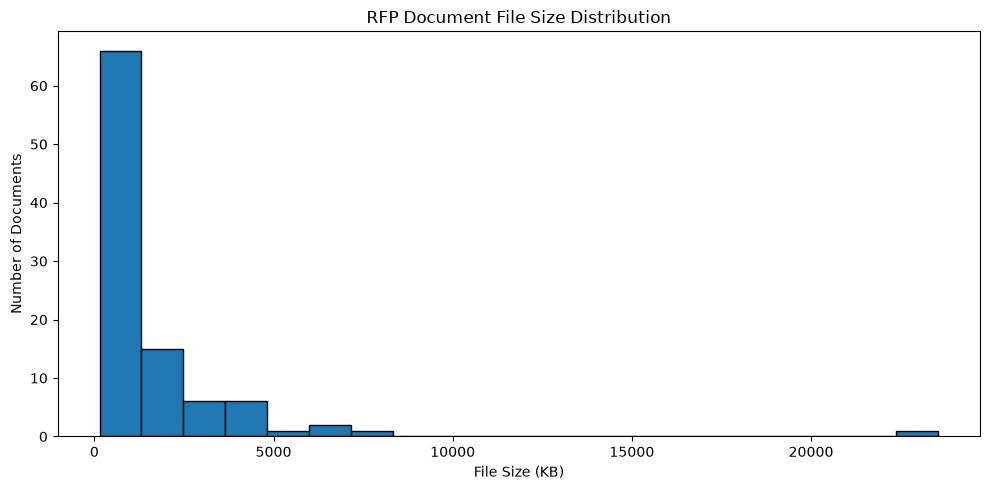

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(19)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# import matplotlib.pyplot as plt
#
# # 파일 크기 기초 통계
# display(df_files["파일크기_KB"].describe().round(2))
#
# # 파일 크기 분포 시각화
# plt.figure(figsize=(10, 5))
#
# plt.hist(df_files["파일크기_KB"], bins=20, edgecolor="black")
#
# plt.title("RFP Document File Size Distribution")
# plt.xlabel("File Size (KB)")
# plt.ylabel("Number of Documents")
# plt.tight_layout()
# plt.show()

#### 분석 결과

98개 문서의 평균 크기는 약 1,685KB이며,
중앙값은 약 950KB로 나타났다.

평균이 중앙값보다 높은 이유는 일부 용량이 큰 문서가
전체 평균에 영향을 주기 때문이다.

특히 가장 큰 문서는 23,546KB로,
일반적인 문서보다 크기가 상당히 컸다.

**분석을 통해 확인한 점**

- 대부분의 문서는 비교적 작은 용량 구간에 분포한다.
- 일부 대용량 문서 때문에 파일 크기의 편차가 크게 나타난다.
- 파일 크기만으로 실제 텍스트 분량이나 전처리 난이도를 판단할 수는 없다.

**다음 확인 사항**

용량이 큰 문서에 이미지, 표, 텍스트 중 어떤 데이터가
많이 포함되어 있는지 파싱 단계에서 확인할 예정이다.

### 2.7 파일 크기가 큰 문서 확인

앞선 분석에서 일부 문서의 파일 크기가
전체 평균보다 상당히 큰 것을 확인했다.

어떤 문서가 큰 용량을 차지하는지 확인하기 위해
파일 크기가 가장 큰 문서 10개를 살펴본다.

이 문서들은 이후 파싱 단계에서
텍스트와 이미지, 표의 추출 결과를 추가로 확인할 예정이다.

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(22)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# # 파일 크기가 큰 문서 10개
# largest_files = df_files.nlargest(10, "파일크기_KB")
#
# display(largest_files)

,파일명,파일형식,파일크기_KB
6,KOICA 전자조달_[긴급] [지문] [국제] 우즈베키스탄 열린 의정활동 상하원 .hwp,.hwp,23546.0
71,한국농어촌공사_아세안+3 식량안보정보시스템(AFSIS) 3단계 협력(캄보디아.hwp,.hwp,7847.0
12,고려대학교_차세대 포털·학사 정보시스템 구축사업.pdf,.pdf,7089.9
70,한국농어촌공사_네팔 수자원관리 정보화사업-Pilot 시스템 구축용역.hwp,.hwp,6767.5
82,한국수자원공사_수도사업장 통합 사고분석솔루션 시범구축 용역.hwp,.hwp,5293.0
36,사단법인아시아물위원회사무국_우즈벡-키르기즈스탄 기후변화대응 스.hwp,.hwp,4681.0
22,국방과학연구소_기록관리시스템 통합 활용 및 보안 환경 구축.hwp,.hwp,4195.5
0,(사)벤처기업협회_2024년 벤처확인종합관리시스템 기능 고도화 용역사업 .hwp,.hwp,4163.0
88,한국연구재단_2024년 대학산학협력활동 실태조사 시스템(UICC) 기능개선.hwp,.hwp,4144.0
62,축산물품질평가원_꿀 품질평가 전산시스템 기능개선 사업.hwp,.hwp,3923.0


#### 분석 결과

파일 크기가 가장 큰 문서 10개를 확인했다.

가장 큰 문서는 KOICA 전자조달 시스템 관련 HWP 파일로,
크기는 약 23MB였다.

상위 10개에는 HWP 9개와 PDF 1개가 포함되어 있다.

**추가 확인 사항**

- 대용량 문서에 이미지가 많이 포함되어 있는가?
- 실제 텍스트 분량도 다른 문서보다 많은가?
- 표나 이미지가 정상적으로 추출되는가?

파일 크기만으로는 원인을 판단할 수 없으므로,
이후 파싱 결과와 비교하여 확인한다.

### 2.8 문서 형식별 파일 크기 비교

HWP와 PDF 문서의 파일 크기에 차이가 있는지 확인한다.

파일 형식별 평균과 중앙값을 비교하여
각 형식의 데이터 특성을 살펴본다.

단, PDF 문서는 4개뿐이므로
두 파일 형식의 일반적인 차이로 해석하지 않는다.

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(25)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# # 파일 형식별 크기 통계
# format_stats = (
#     df_files.groupby("파일형식")["파일크기_KB"]
#     .agg(["count", "mean", "median", "min", "max"])
#     .round(2)
# )
#
# display(format_stats)

,count,mean,median,min,max
파일형식,,,,,
.hwp,94,1618.00,943.75,143.50,23546.0
.pdf,4,3259.09,2659.70,627.07,7089.9


#### 분석 결과

중복을 제외한 98개 문서는 HWP 94개, PDF 4개로 구성되어 있다.

- HWP 평균 크기: 1,618.00KB
- PDF 평균 크기: 3,259.09KB
- HWP 중앙값: 943.75KB
- PDF 중앙값: 2,659.70KB

이번 데이터에서는 PDF의 평균 크기가 HWP보다 약 2배 높았다.

다만 PDF는 4개뿐이므로 파일 형식 자체의 특성이라고 판단하기는 어렵다.

**분석 결과에 따른 판단**

전체 문서의 대부분이 HWP이므로 HWP 파싱을 중점적으로 검증한다.

PDF는 문서 수가 적지만 이미지나 표가 포함될 수 있으므로 별도로 확인한다.

이후 실제 텍스트 추출량과 이미지·표 구성까지 비교하여
파일 크기와 데이터 내용의 관계를 분석한다.

## 3. 원본 문서 파싱

### 3.1 파싱 방법 확인

파싱은 HWP나 PDF 파일에서 본문, 표, 이미지 등의 정보를
Python에서 사용할 수 있는 형태로 추출하는 과정이다.

이번 데이터는 HWP와 PDF로 구성되어 있으므로
파일 형식에 맞는 파싱 방법이 필요하다.

먼저 기존 프로젝트에서 사용한 Loader와 처리 방식을 확인하고,
실제 문서에 적용하여 추출 결과를 살펴본다.

이 과정에서 다음 내용을 확인한다.

- 본문 텍스트가 정상적으로 추출되는가?
- 표의 내용과 구조가 유지되는가?
- 이미지가 정상적으로 추출되는가?
- 원본 내용이 누락되거나 중복되는 부분은 없는가?

파싱 결과를 원본과 비교하여
사용한 방법의 장점과 한계를 기록한다.

### 3.2 HWP Loader 선택 및 실행 환경 확인

전체 98개 문서 중 94개가 HWP 형식이다.

HWP는 일반 텍스트 파일과 달리 본문, 표, 이미지 등
여러 요소가 포함된 문서이므로 전용 파서가 필요하다.

기존 프로젝트에서는 `HwpHwpxLoader`를 사용했다.

이 Loader는 문서의 본문과 표를 구분하여 추출할 수 있어
각 요소의 내용과 구조를 개별적으로 확인하는 데 활용할 수 있다.

**선택한 설정**
- `mode="elements"`: 본문과 표를 요소별로 구분
- `include_tables=True`: 표 추출 활성화
- `TableStyle.MARKDOWN`: 표를 Markdown 형태로 표현

먼저 필요한 라이브러리가 설치되어 있는지 확인한다.

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(29)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# from importlib.metadata import version, PackageNotFoundError
#
# packages = [
#     "langchain-hwp-hwpx-loader",
#     "hwp-hwpx-parser",
#     "pymupdf"
# ]
#
# for package in packages:
#     try:
#         print(f"{package}: {version(package)}")
#     except PackageNotFoundError:
#         print(f"{package}: 설치되지 않음")

langchain-hwp-hwpx-loader: 0.1.1
hwp-hwpx-parser: 1.0.0
pymupdf: 1.28.2


### 3.3 HWP 문서 파싱 및 결과 확인

HWP 문서에서 본문과 표를 추출한다.

이번에는 `HwpHwpxLoader`를 사용하고,
본문과 표를 각각 구분할 수 있도록 `elements` (문서에서 추출한 개별 구성 요소) 모드로 설정한다.

표는 Markdown 형식으로 추출하여
행과 열의 구분이 어떻게 유지되는지 확인한다.

먼저 HWP 문서 1개를 선택하여 추출 결과를 살펴본다.

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(31)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# from langchain_hwp_hwpx import HwpHwpxLoader
# from hwp_hwpx_parser import ExtractOptions, TableStyle
#
# # HWP 문서 1개 선택
# sample_hwp = next(
#     path for path in unique_files
#     if path.suffix.lower() == ".hwp"
# )
#
# print("분석 문서:", unicodedata.normalize("NFC", sample_hwp.name))
#
# # HWP Loader 설정
# loader = HwpHwpxLoader(
#     file_path=sample_hwp,
#     mode="elements",
#     extract_options=ExtractOptions(
#         table_style=TableStyle.MARKDOWN,
#     ),
#     include_tables=True,
# )
#
# # 문서 파싱
# sample_documents = loader.load()
#
# # 추출 결과 확인
# element_counts = Counter(
#     doc.metadata.get("element_type", "unknown")
#     for doc in sample_documents
# )
#
# print("\n전체 Element 수:", len(sample_documents))
# print("Element 유형별 개수:", dict(element_counts))
#
# print("\n추출된 내용 예시:")
# for index, doc in enumerate(sample_documents[:3]):
#     print(f"\n[Element {index + 1}]")
#     print("유형:", doc.metadata.get("element_type"))
#     print("내용:", doc.page_content[:500])

분석 문서: (사)벤처기업협회_2024년 벤처확인종합관리시스템 기능 고도화 용역사업 .hwp

전체 Element 수: 228
Element 유형별 개수: {'body': 1, 'table': 226, 'footnote': 1}

추출된 내용 예시:

[Element 1]
유형: body
내용: |  |  |
| --- | --- |
| 2024년 ｢벤처확인종합관리시스템 기능 고도화｣ 용역사업 (복수의결권주식, 스톡옵션, 성과조건부주식) - 제안요청서 |
|  |  |

2024. 03.
[IMAGE]

|  | 목  차 |  |
| --- | --- | --- |
|  |  |
|  |

목  차
 1. 추진개요	螨ȃ	 3
 2. 추진방안	螨ȃ	 5
 3. 추진내용	螨ȃ	 9
 4. 제안요청내용	砼ȃ	 24
 5. 입찰관련사항	砼ȃ	 78
 6. 제안서작성요령	牠ȃ	 82
 7. 별지서식 및 붙임	沈ȃ	 94

| Ⅰ. 추진개요 |
| --- |


| 1 |  | 추진배경 및 방향 |
| --- | --- | --- |

□ 「벤처기업육성에 관한 특별조치법」(이하 ‘벤처기업법’) 복수의결권주식, 스톡옵션(주식매수선택권), 성과조건부주식교부계약(RS) 등의 기능 고도화 및 이관, 신규 구축업무를 本 과업에서 추진
  ⚬(복수의결권주식*) 벤처기업법 제16조의11에 따라 발

[Element 2]
유형: table
내용: |  |  |
| --- | --- |
| 2024년 ｢벤처확인종합관리시스템 기능 고도화｣ 용역사업 (복수의결권주식, 스톡옵션, 성과조건부주식) - 제안요청서 |
|  |  |

[Element 3]
유형: table
내용: |  | 목  차 |  |
| --- | --- | --- |
|  |  |
|  |


#### 파싱 결과

첫 번째 HWP 문서에서 총 228개의 Element(문서에서 추출한 개별 구성 요소)가 추출되었다.

- Body(본문): 1개
- Table(표): 226개
- Footnote(각주): 1개

### 3.4 본문과 표의 중복 확인

HWP 문서를 파싱하면 Body(본문)에 표 내용이 포함될 수 있다.

이때 별도로 추출한 Table(표)까지 합치면
동일한 내용이 두 번 저장될 가능성이 있다.

따라서 추출된 표가 본문에도 포함되어 있는지 확인한다.

중복이 발견되면 실제 내용을 비교하고,
중복 처리가 필요한 이유를 분석한다.

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(34)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# # Body(본문)와 Table(표) 구분
# body_docs = [
#     doc for doc in sample_documents
#     if doc.metadata.get("element_type") == "body"
# ]
#
# table_docs = [
#     doc for doc in sample_documents
#     if doc.metadata.get("element_type") == "table"
# ]
#
# # 본문 텍스트 추출
# body_text = "\n".join(doc.page_content for doc in body_docs)
#
# # 본문에 동일한 내용이 포함된 표 확인
# duplicated_tables = [
#     doc for doc in table_docs
#     if doc.page_content.strip()
#     and doc.page_content.strip() in body_text
# ]
#
# # 결과 출력
# print("Body(본문):", len(body_docs), "개")
# print("Table(표):", len(table_docs), "개")
# print("본문에 포함된 표:", len(duplicated_tables), "개")
#
# if table_docs:
#     duplicate_rate = len(duplicated_tables) / len(table_docs) * 100
#     print(f"표 중복 비율: {duplicate_rate:.2f}%")

Body(본문): 1 개
Table(표): 226 개
본문에 포함된 표: 213 개
표 중복 비율: 94.25%


#### 분석 결과

총 226개의 표 중 213개(94.25%)가 Body에도 동일하게 포함되어 있었다.

이는 HWP 파싱 과정에서 본문과 표의 내용이 중복 추출될 수 있음을 보여준다.

**발견한 문제**
- Body와 Table을 단순히 합치면 같은 내용이 반복될 수 있다.
- 중복된 내용 때문에 실제보다 텍스트 분량이 많아질 수 있다.
- 검색 과정에서도 동일한 정보가 반복될 가능성이 있다.

**개선 방향**

표를 무조건 삭제하지 않고, Body와 Table의 중복 여부를 확인한 후
원본의 내용과 표 구조를 최대한 보존하는 방법을 검토한다.

※ 현재 중복률은 표 전체 문자열이 Body에 포함된 비율이며,
본문 전체에서 중복 텍스트가 차지하는 비율은 아니다.

### 3.5 중복된 표 실제 확인

중복으로 판단된 표의 실제 내용을 확인한다.

표가 Body에 어떤 형태로 포함되어 있는지 살펴보고,
별도로 추출된 Table과 비교한다.

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(37)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# # 중복된 표 중 첫 번째 표 선택
# sample_table = duplicated_tables[0].page_content.strip()
#
# # Body에서 동일한 표가 등장하는 위치 확인
# start = body_text.find(sample_table)
# end = start + len(sample_table)
#
# print("===== Table에서 추출한 내용 =====")
# print(sample_table[:1000])
#
# print("\n===== Body에서 추출한 동일한 내용 =====")
# print(body_text[start:end][:1000])
#
# print("\n===== 비교 결과 =====")
# print("내용 완전 일치:", sample_table == body_text[start:end])
# print("표 전체 문자 수:", len(sample_table))

===== Table에서 추출한 내용 =====
|  |  |
| --- | --- |
| 2024년 ｢벤처확인종합관리시스템 기능 고도화｣ 용역사업 (복수의결권주식, 스톡옵션, 성과조건부주식) - 제안요청서 |
|  |  |

===== Body에서 추출한 동일한 내용 =====
|  |  |
| --- | --- |
| 2024년 ｢벤처확인종합관리시스템 기능 고도화｣ 용역사업 (복수의결권주식, 스톡옵션, 성과조건부주식) - 제안요청서 |
|  |  |

===== 비교 결과 =====
내용 완전 일치: True
표 전체 문자 수: 98


#### 분석 결과

첫 번째 표를 비교한 결과, Body와 Table에 동일한 내용이 포함되어 있었다.

- 표 길이: 98자
- 내용 일치 여부: True
- 확인 결과: 같은 표가 Body와 Table에 중복 포함됨

이는 표 내용을 별도로 추출하더라도 Body에 동일한 내용이 남아 있을 수 있음을 보여준다.

다만 전체 226개 표 중 13개는 완전히 일치하지 않았다.

이 표들이 실제로 누락된 것인지, 일부 내용만 겹치는 것인지,
표현 방식이 달라진 것인지 추가로 확인한다.

### 3.6 중복되지 않은 표 분석

전체 226개 표 중 13개는 Body에서 동일한 문자열을 찾지 못했다.

이것이 실제 내용 누락을 의미하는 것은 아니다.

표의 일부 내용만 포함되어 있거나,
줄바꿈과 공백 등의 차이로 일치하지 않았을 가능성도 있다.

따라서 해당 표의 내용을 직접 확인한다.

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(40)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# # Body에 전체 문자열이 포함되지 않은 표
# non_duplicated_tables = [
#     doc for doc in table_docs
#     if doc.page_content.strip()
#     and doc.page_content.strip() not in body_text
# ]
#
# print("확인 대상 표:", len(non_duplicated_tables))
#
# # 우선 첫 번째 표 확인
# if non_duplicated_tables:
#     sample = non_duplicated_tables[0]
#
#     print("\n===== Table 내용 =====")
#     print(sample.page_content[:1500])
#
#     print("\n===== Element 메타데이터 =====")
#     print({key: value for key, value in sample.metadata.items() if key not in {"source", "file_name"}})

확인 대상 표: 13

===== Table 내용 =====
|  |  |  |  | 목  차 |  |  |  |  |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |

===== Element 메타데이터 =====
{'file_name': '(사)벤처기업협회_2024년 벤처확인종합관리시스템 기능 고도화 용역사업 .hwp', 'file_type': 'hwp', 'loader': 'langchain_hwp_hwpx/0.1.1', 'parser': 'hwp-hwpx-parser/1.0.0', 'extracted_at': '2026-10-14T23:42:11.566296+00:00', 'element_type': 'table', 'element_index': 3, 'row_count': 1, 'col_count': 9}


#### 중복되지 않은 표의 상세 확인

첫 번째 확인 대상은 '목차'가 포함된 1행 9열 표이다.

이 표는 Body에서 완전히 동일한 문자열을 찾지 못했다.

이는 표가 누락되었기 때문일 수도 있지만,
공백이나 Markdown 표 형식의 차이 때문일 가능성도 있다.

따라서 나머지 표도 확인하여 실제 누락인지,
표현 방식에 따른 차이인지 구분한다.

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(42)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# # 중복되지 않은 표 13개 요약
# table_info = []
#
# for doc in non_duplicated_tables:
#     text = doc.page_content.strip()
#     metadata = doc.metadata
#
#     table_info.append({
#         "Element 번호": metadata.get("element_index"),
#         "행 수": metadata.get("row_count"),
#         "열 수": metadata.get("col_count"),
#         "문자 수": len(text),
#         "내용 미리보기": text[:100].replace("\n", " ")
#     })
#
# df_non_duplicate = pd.DataFrame(table_info)
#
# display(df_non_duplicate)

,Element 번호,행 수,열 수,문자 수,내용 미리보기
0,3,1,9,88,| | | | | 목 차 | | | | | | --- | --- |...
1,10,8,1,491,| | | --- | | 추진과제 | | 세부 실행내용 | | | | | ...
2,11,2,2,114,| 복수의결권주식 | 비상장 벤처기업 조회→보고(발행ㆍ변경)→접수(보완)→공시ㆍ고시...
3,22,10,2,202,| 스톡옵션 | 복수의결권 | | --- | --- | | 제도안내 | 제도안내 |...
4,36,1,2,260,"| | 1. 기업정보, 업무 담당자 입력 간소화 방안 기획 - 기업명, 대표자명 ..."
5,37,4,2,418,"| | 1. 부여주식종류 별도 코드로 관리 2. 액면가 단위(원), 숫자한글정보 ..."
6,62,6,2,156,| 사후변경의 유형 | 전환 여부 | | --- | --- | | 상속 또는 양도 ...
7,75,2,2,67,| 중소벤처기업부 | 스톡옵션 전체 배정 열람 | | --- | --- | | 지방...
8,122,4,3,240,| 구분 | 테스트 내용 | 비고 | | --- | --- | --- | | 단위테...
9,157,4,4,156,| 산출물 종류 | 제출시기 | 수량 | 비고 | | --- | --- | --- ...


### 3.7 표 내용의 부분 중복 확인

앞선 분석에서 13개 표는 Body와 완전히 일치하지 않았다.

하지만 표 전체 문자열이 다르더라도 실제 내용은
본문에 포함되어 있을 수 있다.

이를 확인하기 위해 표의 Markdown 구분 기호와 공백을 제외하고
실제 텍스트가 Body에 존재하는지 비교한다.

이 과정은 데이터를 수정하는 것이 아니라
중복 여부를 확인하기 위한 비교 작업이다.

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(44)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# import re
#
# def normalize_for_comparison(text):
#     # Markdown 표 구분선 제거
#     text = re.sub(r"\|\s*:?-{3,}:?\s*(?=\||$)", "", text)
#
#     # 공백과 표 구분 기호 제거
#     text = re.sub(r"[\s|]", "", text)
#
#     return text
#
#
# # Body 비교용 텍스트
# normalized_body = normalize_for_comparison(body_text)
#
# comparison_results = []
#
# for doc in non_duplicated_tables:
#     table_text = normalize_for_comparison(doc.page_content)
#
#     comparison_results.append({
#         "Element 번호": doc.metadata.get("element_index"),
#         "원본 문자 수": len(doc.page_content),
#         "비교 문자 수": len(table_text),
#         "정규화 후 포함 여부": (
#             bool(table_text) and table_text in normalized_body
#         )
#     })
#
# df_comparison = pd.DataFrame(comparison_results)
#
# display(df_comparison)

,Element 번호,원본 문자 수,비교 문자 수,정규화 후 포함 여부
0,3,88,2,True
1,10,491,339,True
2,11,114,77,True
3,22,202,101,True
4,36,260,190,True
5,37,418,293,False
6,62,156,82,True
7,75,67,32,True
8,122,240,145,True
9,157,156,68,True


#### 분석 결과

처음에는 226개 표 중 13개가 Body와 일치하지 않았다.

공백과 Markdown 표 구분 기호를 제거한 뒤 다시 비교한 결과,
13개 중 12개는 Body에 동일한 문자열이 포함되어 있었다.

**최종 비교 결과**
- 원본 문자열 기준 일치: 213개 (94.25%)
- 정규화 후 추가 일치: 12개
- 정규화 후에도 불일치: 1개
- 전체 일치: 225개 (99.56%)

이를 통해 단순 문자열 비교만으로 중복 여부를 판단하면
공백이나 표 형식 차이 때문에 실제 중복을 놓칠 수 있음을 확인했다.

단, 이 결과는 비교용 문자열의 포함 여부를 확인한 것이며,
표의 행·열 구조까지 동일하다는 의미는 아니다.

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(46)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# # 정규화 후에도 일치하지 않는 표 찾기
# unmatched_tables = [
#     doc for doc in non_duplicated_tables
#     if normalize_for_comparison(doc.page_content)
#     not in normalized_body
# ]
#
# print("최종 불일치 표:", len(unmatched_tables))
#
# for doc in unmatched_tables:
#     print("\nElement 번호:", doc.metadata.get("element_index"))
#     print("행 수:", doc.metadata.get("row_count"))
#     print("열 수:", doc.metadata.get("col_count"))
#
#     print("\n===== Table 전체 내용 =====")
#     print(doc.page_content)
#
#     print("\n===== Body에서 첫 번째 셀 내용 검색 =====")
#
#     # Markdown 표의 실제 셀 내용 추출
#     cells = [
#         cell.strip()
#         for line in doc.page_content.splitlines()
#         if "|" in line
#         for cell in line.split("|")
#         if cell.strip() and not set(cell.strip()) <= {"-", ":"}
#     ]
#
#     for cell in cells[:10]:
#         print(f"{cell[:60]} → {'있음' if cell in body_text else '없음'}")

최종 불일치 표: 1

Element 번호: 37
행 수: 4
열 수: 2

===== Table 전체 내용 =====
|  | 1. 부여주식종류 별도 코드로 관리 2. 액면가 단위(원), 숫자한글정보 표기 3. 부여인원 주식수, 행사가격 총합과 동일해야 함 |
| --- | --- |
|  | 정관에 “스톡옵션(주식매수선택권)주식의 행사기간”이 규정되어 있는지 여부 中 행사기간은 주식매수선택권 부여 결의사항 행사기간과 연동되어 체크되어야 함 |
|  | 1. 주주총회특별결의, 이사회 결의에 따른 입력창, 페이지부터 임시저장 기능 활성화 |
|  | (+)연번 추가를 통한 부여인원 등록, 부여인원 대량등록기능 개발 - 부여인원의 핸드폰번호 등록(개인정보보호에 관한 신고자 대리 등록에 따른 등록 동의) - 핸드폰번호를 통해 부여된 인원의 부여주식 정보 안내 - 자격, 부여방법 코드값으로 관리, - 부여인원 주식 총합 자동 계산 항목별 첨부파일 업로드 복수 |

===== Body에서 첫 번째 셀 내용 검색 =====
1. 부여주식종류 별도 코드로 관리 2. 액면가 단위(원), 숫자한글정보 표기 3. 부여인원 주식수, 행사가 → 있음
정관에 “스톡옵션(주식매수선택권)주식의 행사기간”이 규정되어 있는지 여부 中 행사기간은 주식매수선택권 부여  → 있음
1. 주주총회특별결의, 이사회 결의에 따른 입력창, 페이지부터 임시저장 기능 활성화 → 있음
(+)연번 추가를 통한 부여인원 등록, 부여인원 대량등록기능 개발 - 부여인원의 핸드폰번호 등록(개인정보보호 → 있음


#### 분석 결과

Element 37번은 4행 2열로 구성된 표이다.

표 전체를 비교했을 때는 Body와 일치하지 않았지만,
개별 셀의 텍스트를 검색한 결과 Body에도 해당 내용이 포함되어 있었다.

**현재 확인된 사항**
- 표 전체 문자열: 불일치
- 개별 셀 텍스트: Body에서 발견
- 실제 원문 누락 여부: 아직 확인되지 않음

**추가 검증**

표의 내용을 확인하는 것뿐 아니라 행과 열의 구분이
원본과 동일하게 유지되었는지 확인해야 한다.

따라서 실제 HWP 문서의 표와 추출 결과를 비교한다.

### 3.9 Body와 Table의 구조 차이 확인

앞선 분석에서는 표의 개별 내용이 Body에 존재하는 것을 확인했다.

이번에는 Body에 저장된 내용과 Table의 구조를 비교한다.

이를 통해 단순한 문자열 차이인지,
표의 행과 열이 달라진 것인지 살펴본다.

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(49)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# # Element 37번 선택
# target_table = next(
#     doc for doc in table_docs
#     if doc.metadata.get("element_index") == 37
# )
#
# print("===== Table 원본 추출 결과 =====")
# print(target_table.page_content)
#
# print("\n===== Body 내 관련 내용 =====")
#
# # 표에서 비교할 문자열 선택
# keyword = "부여주식종류 별도 코드로 관리"
#
# # Body에서 해당 문자열의 위치 찾기
# position = body_text.find(keyword)
#
# if position != -1:
#     start = max(0, position - 200)
#     end = min(len(body_text), position + 1000)
#
#     print(body_text[start:end])
# else:
#     print("Body에서 동일한 문자열을 찾지 못했습니다.")

===== Table 원본 추출 결과 =====
|  | 1. 부여주식종류 별도 코드로 관리 2. 액면가 단위(원), 숫자한글정보 표기 3. 부여인원 주식수, 행사가격 총합과 동일해야 함 |
| --- | --- |
|  | 정관에 “스톡옵션(주식매수선택권)주식의 행사기간”이 규정되어 있는지 여부 中 행사기간은 주식매수선택권 부여 결의사항 행사기간과 연동되어 체크되어야 함 |
|  | 1. 주주총회특별결의, 이사회 결의에 따른 입력창, 페이지부터 임시저장 기능 활성화 |
|  | (+)연번 추가를 통한 부여인원 등록, 부여인원 대량등록기능 개발 - 부여인원의 핸드폰번호 등록(개인정보보호에 관한 신고자 대리 등록에 따른 등록 동의) - 핸드폰번호를 통해 부여된 인원의 부여주식 정보 안내 - 자격, 부여방법 코드값으로 관리, - 부여인원 주식 총합 자동 계산 항목별 첨부파일 업로드 복수 |

===== Body 내 관련 내용 =====
 등을 통한 주식매수선택권 부여 신고 가능 조회기능 탑재 3. 벤처확인정보 연계 -벤처확인발급번호, 벤처확인일, 유효시간 ※ 벤처확인이력조회가 되지 않는 경우 문의 case1. 벤처확인만료 case2. 사업자등록번호와 벤처확인정보 불일치 case3. 벤처확인만료일 기준 벤처재확인 프로세스 진행 中 |
| --- | --- |


| [IMAGE] | 1. 부여주식종류 별도 코드로 관리 2. 액면가 단위(원), 숫자한글정보 표기 3. 부여인원 주식수, 행사가격 총합과 동일해야 함 |
| --- | --- |
| [IMAGE] | 정관에 “스톡옵션(주식매수선택권)주식의 행사기간”이 규정되어 있는지 여부 中 행사기간은 주식매수선택권 부여 결의사항 행사기간과 연동되어 체크되어야 함 |
| [IMAGE] | 1. 주주총회특별결의, 이사회 결의에 따른 입력창, 페이지부터 임시저장 기능 활성화 |
| [IMAGE] | (+)연번 추가를 통한 부여인원 등록, 부여인원 대량등록기능 개발 - 부여인원의 핸드폰번호 등록(개인정보보호에 관한 신고자 대리

#### 분석 결과

Element 37번이 Body와 일치하지 않은 이유를 확인했다.

- Table: 첫 번째 열이 빈 셀로 추출됨
- Body: 첫 번째 열에 `[IMAGE]` 표시가 포함됨
- 두 번째 열: 동일한 요구사항 텍스트가 포함됨

즉, 표의 주요 텍스트는 양쪽에 존재하지만
이미지 표시 방식이 달라 전체 문자열 비교에서 불일치했다.

**분석을 통해 확인한 점**

1. 단순 문자열 비교만으로 데이터 누락 여부를 판단할 수 없다.
2. 이미지가 포함된 표는 일반 텍스트 표와 다르게 처리될 수 있다.
3. 원본 표의 이미지와 셀 구조를 별도로 확인해야 한다.

**향후 처리 방향**

이미지 표시를 무조건 제거하지 않고,
실제 이미지에 중요한 정보가 포함되어 있는지 확인한다.

이를 통해 원본 정보를 최대한 보존하는 전처리 방법을 결정한다.

### 3.10 이미지가 포함된 표 확인

앞선 분석에서 Body에는 `[IMAGE]`가 표시되지만
Table에서는 해당 셀이 비어 있는 사례를 발견했다.

따라서 HWP 문서에서 이미지가 실제로 추출되었는지 확인하고,
이미지에 포함된 정보가 누락되지 않았는지 검증할 필요가 있다.

먼저 파싱 결과의 메타데이터를 확인하여
이미지와 관련된 정보가 저장되어 있는지 살펴본다.

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(52)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# # Element 유형별 메타데이터 확인 (개인 경로 제외)
#
# for index, doc in enumerate(sample_documents[:10]):
#     print(f"\n===== Element {index} =====")
#     print("유형:", doc.metadata.get("element_type"))
#
#     # 개인 경로가 포함될 수 있는 항목 제외
#     safe_metadata = {
#         key: value
#         for key, value in doc.metadata.items()
#         if key not in {"source", "file_name"}
#     }
#
#     print("메타데이터:", safe_metadata)


===== Element 0 =====
유형: body
메타데이터: {'file_type': 'hwp', 'loader': 'langchain_hwp_hwpx/0.1.1', 'parser': 'hwp-hwpx-parser/1.0.0', 'extracted_at': '2026-10-14T23:42:11.566296+00:00', 'element_type': 'body', 'element_index': 0}

===== Element 1 =====
유형: table
메타데이터: {'file_type': 'hwp', 'loader': 'langchain_hwp_hwpx/0.1.1', 'parser': 'hwp-hwpx-parser/1.0.0', 'extracted_at': '2026-10-14T23:42:11.566296+00:00', 'element_type': 'table', 'element_index': 1, 'row_count': 3, 'col_count': 2}

===== Element 2 =====
유형: table
메타데이터: {'file_type': 'hwp', 'loader': 'langchain_hwp_hwpx/0.1.1', 'parser': 'hwp-hwpx-parser/1.0.0', 'extracted_at': '2026-10-14T23:42:11.566296+00:00', 'element_type': 'table', 'element_index': 2, 'row_count': 3, 'col_count': 3}

===== Element 3 =====
유형: table
메타데이터: {'file_type': 'hwp', 'loader': 'langchain_hwp_hwpx/0.1.1', 'parser': 'hwp-hwpx-parser/1.0.0', 'extracted_at': '2026-10-14T23:42:11.566296+00:00', 'element_type': 'table', 'element_index': 3, 'row_count': 1

### 3.10 이미지 관련 메타데이터 확인

HWP 문서를 파싱하는 과정에서 `[IMAGE]` 표시가 발견되었다.

이 표시만으로는 실제 이미지가 추출되었는지 알 수 없다.

따라서 Element의 메타데이터를 확인하여
이미지 저장 경로와 OCR 처리 정보가 존재하는지 살펴본다.

개인 컴퓨터 경로는 GitHub에 노출되지 않도록 출력하지 않는다.

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(54)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# import pandas as pd
#
# # 전체 메타데이터 항목 확인
# metadata_keys = sorted({
#     key
#     for doc in sample_documents
#     for key in doc.metadata
# })
#
# print("전체 메타데이터 항목:")
# print(metadata_keys)
#
# # 이미지 및 OCR 관련 정보만 확인
# image_keywords = ("image", "ocr")
#
# image_metadata = []
#
# for index, doc in enumerate(sample_documents):
#     for key, value in doc.metadata.items():
#
#         if any(word in key.lower() for word in image_keywords):
#             image_metadata.append({
#                 "Element 번호": index,
#                 "항목": key,
#                 "정보 존재 여부": value is not None,
#                 "값 유형": type(value).__name__
#             })
#
# df_image_metadata = pd.DataFrame(image_metadata)
#
# print("\n이미지 관련 메타데이터:", len(df_image_metadata), "건")
#
# display(df_image_metadata.head(20))

전체 메타데이터 항목:
['col_count', 'element_index', 'element_type', 'extracted_at', 'file_name', 'file_type', 'loader', 'note_number', 'note_type', 'parser', 'row_count', 'source']

이미지 관련 메타데이터: 0 건


""


#### 분석 결과

전체 Element의 메타데이터를 확인한 결과,
이미지 저장 경로나 OCR 관련 항목은 발견되지 않았다.

반면 Body에는 `[IMAGE]` 표시가 존재한다.

**확인된 문제**
- 이미지가 포함된 위치는 일부 확인할 수 있다.
- 실제 이미지 파일과 이미지 속 텍스트는 아직 확인하지 못했다.
- 이미지 속 중요한 정보가 누락되었을 가능성이 있다.

따라서 기존 이미지 추출 방법을 확인하고,
실제 이미지를 출력하여 내용을 검증한다.

### 3.11 이미지 추출 결과 확인

앞선 분석에서 Body에 `[IMAGE]` 표시가 있지만,
이미지 관련 메타데이터는 없는 것을 확인했다.

이번에는 기존 전처리 과정에서 저장한 이미지 파일이 있는지 확인한다.

이미지가 저장되어 있다면 실제 이미지를 출력하고,
텍스트나 표 등 중요한 정보가 포함되어 있는지 육안으로 검증한다.

이미지 속 정보가 누락되었다면 OCR 적용 여부를 검토한다.

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(57)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# # 기존 전처리 과정에서 저장된 이미지 경로 확인
# image_paths = []
#
# if "saved_image_documents" in globals():
#     for doc in saved_image_documents:
#         saved_path = doc.metadata.get("saved_path")
#
#         if saved_path and Path(saved_path).is_file():
#             image_paths.append(Path(saved_path))
#
# print("저장된 이미지:", len(image_paths), "개")
#
# if image_paths:
#     print("이미지 파일 확인 완료")
# else:
#     print("현재 Notebook에서 저장된 이미지를 찾지 못했습니다.")

저장된 이미지: 0 개
현재 Notebook에서 저장된 이미지를 찾지 못했습니다.


### 3.12 HWP 이미지 추출

기존 파싱에서는 본문과 표를 추출했지만,
이미지 파일은 별도로 저장하지 않았다.

이미지에는 화면 구성, 업무 절차, 손글씨 등
중요한 정보가 포함될 수 있다.

따라서 이미지 추출 기능을 활성화하여 다시 파싱한다.

**설정 및 선택 이유**
- `include_images=True`: 이미지도 함께 추출한다.
- `images_dir`: 추출된 이미지를 별도 폴더에 저장한다.
- `image_document_mode="save_and_reference"`: 이미지 파일을 저장하고 관련 정보를 기록한다.

원본 HWP 파일은 변경하지 않는다.

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(59)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# # 이미지 저장 폴더 설정
# IMAGE_DIR = PROJECT_DIR / "outputs" / "images"
# IMAGE_DIR.mkdir(parents=True, exist_ok=True)
#
# # 이미지 추출 옵션을 활성화한 Loader
# image_loader = HwpHwpxLoader(
#     file_path=sample_hwp,
#     mode="elements",
#     extract_options=ExtractOptions(
#         table_style=TableStyle.MARKDOWN,
#     ),
#     include_tables=True,
#     include_images=True,
#     images_dir=IMAGE_DIR,
#     image_document_mode="save_and_reference",
# )
#
# # 이미지 포함 문서 파싱
# sample_documents_with_images = image_loader.load()
#
# # 이미지 Element만 분리
# saved_image_documents = [
#     doc for doc in sample_documents_with_images
#     if doc.metadata.get("element_type") == "image"
# ]
#
# # 추출 결과 확인
# print("전체 Element:", len(sample_documents_with_images))
# print("추출된 이미지:", len(saved_image_documents))
#
# for index, doc in enumerate(saved_image_documents):
#     saved_path = doc.metadata.get("saved_path")
#     image_path = Path(saved_path) if saved_path else None
#
#     print(
#         f"이미지 {index}:",
#         image_path.name if image_path else "저장 경로 없음",
#         "| 저장 확인:",
#         image_path.is_file() if image_path else False
#     )

전체 Element: 237
추출된 이미지: 9
이미지 0: BIN0001.png | 저장 확인: True
이미지 1: BIN0002.jpg | 저장 확인: True
이미지 2: BIN0003.bmp | 저장 확인: True
이미지 3: BIN0004.bmp | 저장 확인: True
이미지 4: BIN0005.jpg | 저장 확인: True
이미지 5: BIN0006.jpg | 저장 확인: True
이미지 6: BIN0007.jpg | 저장 확인: True
이미지 7: BIN0008.jpg | 저장 확인: True
이미지 8: BIN0009.jpg | 저장 확인: True


#### 분석 결과

이미지 추출 옵션을 활성화한 결과, 총 9개의 이미지가 추출되었다.

- 기존 Element: 228개
- 이미지 추출 후 Element: 237개
- 추출된 이미지: 9개
- 이미지 저장 확인: 9개 모두 성공

**확인한 점**

기존 파싱에서는 이미지가 별도 Element로 추출되지 않았다.

이미지 추출 기능을 활성화하자 9개의 이미지가 추가되었으며,
이를 통해 텍스트뿐 아니라 이미지도 별도로 확인할 수 있게 되었다.

다음 단계에서는 실제 이미지를 출력하고
중요한 정보가 포함되어 있는지 확인한다.

### 3.13 추출 이미지 육안 검증

추출된 이미지 9개를 직접 확인한다.

이미지의 종류와 내용을 살펴보고,
텍스트나 표 등 중요한 정보가 포함되어 있는지 확인한다.

특히 이미지 속 텍스트가 일반 파싱 과정에서 누락되었는지 살펴본다.

공개본에서는 원본/확대 이미지를 제외하고 검토 목적과 숫자 결과만 유지합니다.

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(62)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# from IPython.display import display
# from PIL import Image
#
# # 추출된 이미지 9개 확인
# for index, doc in enumerate(saved_image_documents):
#
#     saved_path = doc.metadata.get("saved_path")
#
#     if not saved_path:
#         print(f"이미지 {index + 1}: 저장 경로 없음")
#         continue
#
#     image_path = Path(saved_path)
#
#     if not image_path.is_file():
#         print(f"이미지 {index + 1}: 파일 없음")
#         continue
#
#     print(f"\n===== 이미지 {index + 1}: {image_path.name} =====")
#
#     try:
#         with Image.open(image_path) as img:
#             print("크기:", img.size, "| 형식:", img.format)
#
#             preview = img.copy()
#             preview.thumbnail((1000, 700))
#             display(preview)
#
#     except Exception as error:
#         print("이미지 열기 실패:", type(error).__name__)

공유본에서는 원본 이미지·서명·직인 및 확대 화면을 표시하지 않습니다. 기존 수치·분류·OCR 비교 표를 참고하세요.


#### 분석 결과

추출된 이미지에서 표, 인쇄된 텍스트, 손글씨 등이 확인되었다.

**발견한 특징**
- 일부 이미지는 문서 전체가 스캔된 형태이다.
- 이미지 안에 표와 손글씨가 함께 포함되어 있다.
- 일반 텍스트 파싱으로는 이미지 내부의 내용을 직접 추출할 수 없다.

**처리 방향**

이미지를 유형별로 분류한 후 OCR 적용 여부를 결정한다.

특히 손글씨는 OCR 결과가 부정확할 수 있으므로
원본 이미지를 직접 확인하고 필요한 경우 수동으로 보완한다.

개인정보가 포함된 이미지는 공개하지 않고,
검증 결과만 Notebook에 기록한다.

### 3.14 이미지 유형별 분류

추출된 이미지 9개의 크기와 형식을 확인하고,
어떤 이미지에 OCR이 필요한지 판단하기 위한 목록을 만든다.

이미지의 실제 내용은 육안으로 확인한 후 분류한다.

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(65)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# image_info = []
#
# for index, doc in enumerate(saved_image_documents, 1):
#     image_path = Path(doc.metadata["saved_path"])
#
#     with Image.open(image_path) as img:
#         image_info.append({
#             "이미지 번호": index,
#             "파일명": image_path.name,
#             "형식": img.format,
#             "가로": img.width,
#             "세로": img.height,
#             "이미지 유형": "검토 필요",
#             "OCR 필요 여부": "검토 필요",
#             "육안 검증": "미완료"
#         })
#
# df_images = pd.DataFrame(image_info)
#
# display(df_images)

,이미지 번호,파일명,형식,가로,세로,이미지 유형,OCR 필요 여부,육안 검증
0,1,BIN0001.png,PNG,591,811,검토 필요,검토 필요,미완료
1,2,BIN0002.jpg,JPEG,2163,5723,검토 필요,검토 필요,미완료
2,3,BIN0003.bmp,BMP,691,411,검토 필요,검토 필요,미완료
3,4,BIN0004.bmp,BMP,507,78,검토 필요,검토 필요,미완료
4,5,BIN0005.jpg,JPEG,579,558,검토 필요,검토 필요,미완료
5,6,BIN0006.jpg,JPEG,700,337,검토 필요,검토 필요,미완료
6,7,BIN0007.jpg,JPEG,700,529,검토 필요,검토 필요,미완료
7,8,BIN0008.jpg,JPEG,700,222,검토 필요,검토 필요,미완료
8,9,BIN0009.jpg,JPEG,700,514,검토 필요,검토 필요,미완료


### 3.15 이미지 육안 검증 및 분류

추출된 이미지 9개를 직접 확인하여 유형별로 분류한다.

이미지에 텍스트가 포함되어 있는지, OCR이 필요한지,
손글씨 등 추가 검증이 필요한 부분이 있는지 확인한다.

**분류 기준**
- 일반 이미지: 로고, 그림 등
- 인쇄 문서: 인쇄된 글자나 표가 포함된 이미지
- 손글씨 포함: 사람이 직접 작성한 글자가 포함된 이미지
- 혼합 이미지: 인쇄된 글자와 손글씨가 함께 있는 이미지

이미지 유형에 따라 OCR 적용 및 수동 검증 여부를 결정한다.

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(67)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# # 이미지 육안 검증 결과
# image_reviews = {
#     1: ("혼합 이미지", "필요"),
#     2: ("인쇄 문서", "필요"),
#     3: ("일반 이미지", "불필요"),
#     4: ("일반 이미지", "불필요"),
#     5: ("화면 캡처", "필요"),
#     6: ("화면 캡처", "필요"),
#     7: ("화면 캡처", "필요"),
#     8: ("화면 캡처", "필요"),
#     9: ("화면 캡처", "필요"),
# }
#
# # 검토 결과 반영
# for image_num, (image_type, ocr_needed) in image_reviews.items():
#
#     mask = df_images["이미지 번호"] == image_num
#
#     df_images.loc[mask, "이미지 유형"] = image_type
#     df_images.loc[mask, "OCR 필요 여부"] = ocr_needed
#     df_images.loc[mask, "육안 검증"] = "분류 완료"
#
# # 결과 확인
# display(df_images)
#
# print("\n이미지 유형별 개수")
# display(df_images["이미지 유형"].value_counts())
#
# print("\nOCR 필요 여부")
# display(df_images["OCR 필요 여부"].value_counts())

,이미지 번호,파일명,형식,가로,세로,이미지 유형,OCR 필요 여부,육안 검증
0,1,BIN0001.png,PNG,591,811,혼합 이미지,필요,분류 완료
1,2,BIN0002.jpg,JPEG,2163,5723,인쇄 문서,필요,분류 완료
2,3,BIN0003.bmp,BMP,691,411,일반 이미지,불필요,분류 완료
3,4,BIN0004.bmp,BMP,507,78,일반 이미지,불필요,분류 완료
4,5,BIN0005.jpg,JPEG,579,558,화면 캡처,필요,분류 완료
5,6,BIN0006.jpg,JPEG,700,337,화면 캡처,필요,분류 완료
6,7,BIN0007.jpg,JPEG,700,529,화면 캡처,필요,분류 완료
7,8,BIN0008.jpg,JPEG,700,222,화면 캡처,필요,분류 완료
8,9,BIN0009.jpg,JPEG,700,514,화면 캡처,필요,분류 완료



이미지 유형별 개수


이미지 유형
화면 캡처     5
일반 이미지    2
혼합 이미지    1
인쇄 문서     1
Name: count, dtype: int64


OCR 필요 여부


OCR 필요 여부
필요     7
불필요    2
Name: count, dtype: int64

#### 분석 결과

대표 HWP 문서에서 추출한 이미지 9개를 육안으로 확인했다.

- 화면 캡처: 5개
- 일반 이미지: 2개
- 혼합 이미지: 1개
- 인쇄 문서: 1개

**OCR 적용 대상은 총 7개로 선정했다.**

기관 로고와 장식용 이미지는 OCR 대상에서 제외했다.
반면 시스템 화면, 평가 결과표, 손글씨가 포함된 이미지는
중요한 정보가 담겨 있어 OCR 대상으로 선정했다.

특히 손글씨와 작은 글자는 인식 오류가 발생할 수 있으므로
OCR 처리 후 실제 이미지와 비교하여 정확성을 검증할 예정이다.

현재는 이미지 유형 분류를 완료한 상태이며,
OCR 처리와 텍스트 검증은 아직 진행하지 않았다.

### 3.16 OCR 실행 환경 확인

OCR은 이미지에 포함된 글자를 텍스트로 변환하는 기술이다.

이미지에서 글자를 추출하려면 OCR 엔진이 필요하다.

먼저 현재 환경에서 사용할 수 있는 OCR 도구와
한국어 인식 기능이 설치되어 있는지 확인한다.

이후 실제 이미지에 OCR을 적용하고,
추출 결과를 원본과 비교하여 정확성을 검증한다.

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(70)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# import importlib.util
# import shutil
# import subprocess
#
# # Python OCR 라이브러리 확인
# ocr_packages = ["pytesseract", "easyocr", "paddleocr"]
#
# print("===== OCR 라이브러리 확인 =====")
#
# for package in ocr_packages:
#     installed = importlib.util.find_spec(package) is not None
#     print(f"{package}: {'설치됨' if installed else '설치되지 않음'}")
#
# # Tesseract OCR 엔진 확인
# tesseract_path = shutil.which("tesseract")
#
# print("\n===== Tesseract OCR 엔진 =====")
#
# if tesseract_path:
#     print("Tesseract: 설치됨")
#
#     result = subprocess.run(
#         ["tesseract", "--list-langs"],
#         capture_output=True,
#         text=True
#     )
#
#     print("지원 언어:")
#     print(result.stdout or result.stderr)
# else:
#     print("Tesseract: 설치되지 않음")

===== OCR 라이브러리 확인 =====
pytesseract: 설치되지 않음
easyocr: 설치됨
paddleocr: 설치되지 않음

===== Tesseract OCR 엔진 =====
Tesseract: 설치되지 않음


### 3.17 EasyOCR을 이용한 이미지 텍스트 추출

현재 환경에는 EasyOCR이 설치되어 있다.

먼저 인쇄된 글자가 포함된 이미지 2번을 대상으로
한국어와 영어 텍스트를 추출한다.

추출 결과를 원본 이미지와 비교하여
글자가 정상적으로 인식되는지 확인한다.

이번 테스트는 OCR 방식의 성능을 확인하기 위한 실험이며,
기존 전처리 결과를 변경하지 않는다.

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(72)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# import easyocr
#
# # 한국어 및 영어 OCR 모델 준비
# reader = easyocr.Reader(["ko", "en"], gpu=False)
#
# # 이미지 2번 선택
# image_path = Path(saved_image_documents[1].metadata["saved_path"])
#
# # OCR 실행
# ocr_results = reader.readtext(str(image_path))
#
# print("인식된 텍스트 영역:", len(ocr_results), "개")
#
# # 결과 출력 (좌표와 개인정보 노출 최소화)
# for index, (bbox, text, confidence) in enumerate(ocr_results[:20], 1):
#     print(f"{index}. 신뢰도: {confidence:.2f} | 글자 수: {len(text)}")

인식된 텍스트 영역: 91 개
1. 신뢰도: 0.88 | 글자 수: 19
2. 신뢰도: 0.99 | 글자 수: 3
3. 신뢰도: 0.58 | 글자 수: 29
4. 신뢰도: 0.66 | 글자 수: 11
5. 신뢰도: 0.24 | 글자 수: 17
6. 신뢰도: 1.00 | 글자 수: 6
7. 신뢰도: 0.42 | 글자 수: 28
8. 신뢰도: 1.00 | 글자 수: 3
9. 신뢰도: 0.98 | 글자 수: 5
10. 신뢰도: 0.99 | 글자 수: 5
11. 신뢰도: 1.00 | 글자 수: 2
12. 신뢰도: 0.97 | 글자 수: 8
13. 신뢰도: 0.24 | 글자 수: 13
14. 신뢰도: 1.00 | 글자 수: 2
15. 신뢰도: 1.00 | 글자 수: 8
16. 신뢰도: 0.91 | 글자 수: 5
17. 신뢰도: 0.92 | 글자 수: 6
18. 신뢰도: 1.00 | 글자 수: 2
19. 신뢰도: 1.00 | 글자 수: 2
20. 신뢰도: 1.00 | 글자 수: 3


### 3.18 OCR 추출 결과 검증

EasyOCR을 이용해 이미지 2번에서 총 91개의 텍스트 영역을 인식했다.

OCR 신뢰도는 인식 결과에 대한 모델의 확신 정도를 나타내며,
실제 정확도와는 차이가 있을 수 있다.

따라서 OCR이 추출한 텍스트를 확인하고,
원본 이미지와 비교하여 오류나 누락 여부를 검증한다.

개인정보가 포함될 수 있으므로 전체 텍스트를 출력하지 않고,
우선 인식 결과의 통계와 검토가 필요한 영역을 확인한다.

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(74)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# import pandas as pd
#
# # OCR 결과 정리
# ocr_info = []
#
# for index, (bbox, text, confidence) in enumerate(ocr_results, 1):
#     ocr_info.append({
#         "번호": index,
#         "글자 수": len(text),
#         "신뢰도": round(confidence, 3),
#         "검토 필요": confidence < 0.7
#     })
#
# df_ocr = pd.DataFrame(ocr_info)
#
# print("전체 인식 영역:", len(df_ocr))
# print("평균 신뢰도:", round(df_ocr["신뢰도"].mean(), 3))
# print("최소 신뢰도:", round(df_ocr["신뢰도"].min(), 3))
# print("신뢰도 0.7 미만:", df_ocr["검토 필요"].sum(), "개")
#
# print("\n신뢰도가 낮은 영역 TOP 10")
# display(
#     df_ocr.sort_values("신뢰도").head(10)
# )

전체 인식 영역: 91
평균 신뢰도: 0.772
최소 신뢰도: 0.004
신뢰도 0.7 미만: 31 개

신뢰도가 낮은 영역 TOP 10


,번호,글자 수,신뢰도,검토 필요
88,89,3,0.004,True
90,91,2,0.026,True
12,13,13,0.239,True
50,51,42,0.241,True
4,5,17,0.244,True
53,54,39,0.263,True
65,66,39,0.284,True
72,73,27,0.313,True
74,75,55,0.357,True
78,79,31,0.360,True


#### 분석 결과

EasyOCR을 이용해 이미지 2번을 분석한 결과,
총 91개의 텍스트 영역이 인식되었다.

- 평균 신뢰도: 0.772
- 최소 신뢰도: 0.004
- 신뢰도 0.7 미만: 31개 (34.1%)

전체 인식 영역 중 약 34%는 신뢰도가 0.7 미만이었다.

이는 OCR 결과에 추가 검토가 필요한 영역이
상당수 존재한다는 것을 의미한다.

다만 OCR 신뢰도는 실제 정답률이 아니므로,
신뢰도가 낮은 영역뿐 아니라 높은 영역도 원본과 비교해야 한다.

**다음 검증**

신뢰도가 가장 낮은 영역을 실제 이미지에서 확인하고,
어떤 글자가 잘못 인식되었는지 분석한다.

### 3.19 OCR 오류 의심 영역 확인

OCR 신뢰도가 가장 낮은 영역 5개를 원본 이미지에서 확인한다.

각 영역의 위치를 표시하고 실제 글자를 살펴본다.

이를 통해 글자 크기, 해상도, 표 구조 등
OCR 오류가 발생한 원인을 분석한다.

원본 이미지는 수정하지 않으며,
개인정보가 포함된 이미지는 GitHub에 공개하지 않는다.

공개본에서는 원본/확대 이미지를 제외하고 검토 목적과 숫자 결과만 유지합니다.

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(77)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# from PIL import Image
# from IPython.display import display
#
# # 신뢰도가 가장 낮은 영역 5개
# low_confidence = df_ocr.nsmallest(5, "신뢰도")
#
# with Image.open(image_path) as img:
#
#     for _, row in low_confidence.iterrows():
#
#         index = int(row["번호"]) - 1
#         bbox, text, confidence = ocr_results[index]
#
#         # OCR 영역 좌표
#         x1 = max(0, int(min(p[0] for p in bbox)) - 10)
#         y1 = max(0, int(min(p[1] for p in bbox)) - 10)
#         x2 = min(img.width, int(max(p[0] for p in bbox)) + 10)
#         y2 = min(img.height, int(max(p[1] for p in bbox)) + 10)
#
#         if x2 <= x1 or y2 <= y1:
#             continue
#
#         # 해당 영역만 잘라서 확대
#         cropped = img.crop((x1, y1, x2, y2))
#         cropped.thumbnail((800, 300))
#
#         print(f"\n영역 번호: {index + 1}")
#         print(f"OCR 신뢰도: {confidence:.3f}")
#
#         display(cropped)

공유본에서는 원본 이미지·서명·직인 및 확대 화면을 표시하지 않습니다. 기존 수치·분류·OCR 비교 표를 참고하세요.


#### 분석 결과

신뢰도가 가장 낮은 5개 영역을 원본 이미지에서 확인했다.

**발견한 문제**

- 직인은 글자가 겹쳐 있어 인식하기 어려운 형태였다.
- 일부 영역은 글자가 잘리거나 다른 요소와 겹쳐 있었다.
- 비교적 선명한 인쇄 글씨에서도 낮은 신뢰도가 나타났다.

**분석 결과에 따른 판단**

OCR 신뢰도만으로 실제 인식 정확도를 판단하기 어렵다.

따라서 OCR로 추출한 텍스트를 원본과 직접 비교하고,
오류가 발생한 영역의 특징을 분석하기로 했다.

특히 직인과 일반 인쇄 문서는 특성이 다르므로
구분하여 검증할 필요가 있다.

### 3.20 OCR 추출 텍스트 검증

앞서 확인한 영역 중 일반 인쇄 글씨 3개를 선택하여
OCR 추출 결과를 확인한다.

원본 이미지와 추출 텍스트를 비교하여
잘못 인식되거나 누락된 글자가 있는지 확인한다.

이 결과를 바탕으로 추가적인 이미지 전처리나
OCR 보완이 필요한지 판단한다.

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(80)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# # 일반 인쇄 글씨 영역 선택
# review_numbers = [13, 51, 5]
#
# for number in review_numbers:
#     bbox, text, confidence = ocr_results[number - 1]
#
#     print(f"\n===== 영역 {number} =====")
#     print("OCR 신뢰도:", round(confidence, 3))
#     print("OCR 추출 결과:", text)


===== 영역 13 =====
OCR 신뢰도: 0.239
OCR 추출 결과: 스톱업선(주식매수선택권)

===== 영역 51 =====
OCR 신뢰도: 0.241
OCR 추출 결과: 주요기능과   동일- 유사한   서비스틀   민간에서   제공하는지   여부

===== 영역 5 =====
OCR 신뢰도: 0.244
OCR 추출 결과: 복수의결권 스튜움선  성과조건부


#### 분석 결과

OCR 신뢰도가 낮은 인쇄 텍스트 3개 영역을 확인했다.

세 영역 모두 주요 글자는 원본과 일치했지만,
일부 영역에서는 띄어쓰기 차이가 발견되었다.

**발견한 점**

- OCR 신뢰도가 낮아도 텍스트가 정확하게 인식될 수 있다.
- 글자 인식과 띄어쓰기 정확도는 구분해서 확인해야 한다.
- OCR 신뢰도만으로 텍스트를 삭제하거나 수정하는 것은 적절하지 않다.

**처리 방향**

원본과 OCR 결과를 비교하여 실제 오류를 확인한다.

띄어쓰기나 특수문자 차이는 별도로 기록하고,
원본의 의미를 변경하지 않는 범위에서 정제 여부를 결정한다.

### 3.21 OCR 텍스트 정확도 비교

앞서 확인한 3개 영역의 원본 텍스트와 OCR 결과를 비교한다.

단순 문자열 일치 여부뿐 아니라
공백을 제외했을 때도 동일한지 확인한다.

이를 통해 실제 글자 인식 오류와
띄어쓰기 차이를 구분한다.

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(83)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# from difflib import SequenceMatcher
# import re
# import pandas as pd
#
# # 원본 이미지를 보고 확인한 텍스트
# reference_texts = {
#     13: "스톡옵션(주식매수선택권)",
#     51: "주요기능과 동일·유사한 서비스를 민간에서 제공하는지 여부",
#     5: "복수의결권, 스톡옵션, 성과조건부",
# }
#
# comparison = []
#
# for number, original in reference_texts.items():
#     _, extracted, confidence = ocr_results[number - 1]
#
#     # 공백 제거 후 비교
#     original_clean = re.sub(r"\s+", "", original)
#     extracted_clean = re.sub(r"\s+", "", extracted)
#
#     similarity = SequenceMatcher(
#         None, original_clean, extracted_clean
#     ).ratio() * 100
#
#     comparison.append({
#         "영역": number,
#         "OCR 신뢰도": round(confidence, 3),
#         "원문 일치": original == extracted,
#         "공백 제거 후 일치": original_clean == extracted_clean,
#         "문자열 유사도(%)": round(similarity, 2)
#     })
#
# df_ocr_comparison = pd.DataFrame(comparison)
#
# display(df_ocr_comparison)

,영역,OCR 신뢰도,원문 일치,공백 제거 후 일치,문자열 유사도(%)
0,13,0.239,False,False,76.92
1,51,0.241,False,False,92.31
2,5,0.244,False,False,73.33


#### 분석 결과

OCR로 추출한 텍스트와 육안으로 확인한 원문을 비교했다.

세 영역의 문자열 유사도는 각각 76.92%, 92.31%, 73.33%로 나타났다.

공백을 제거한 후에도 세 영역 모두 완전히 일치하지 않았다.

**확인한 점**

- OCR 결과에는 띄어쓰기 외에도 문자 차이가 존재한다.
- OCR 신뢰도와 문자열 유사도는 서로 다른 지표이다.
- 정확한 오류 분석을 위해 어떤 문자가 달라졌는지 확인해야 한다.

※ 현재 유사도는 전체 OCR 정확도가 아니라 선택한 세 영역의 비교 결과이다.

### 3.22 OCR 문자 오류 상세 분석

OCR이 원본의 어떤 문자를 잘못 인식했는지 확인한다.

원문과 OCR 결과를 나란히 비교하고,
글자가 변경되거나 누락된 부분을 찾아본다.

이를 통해 OCR 오류의 유형을 파악하고
수동 보완이 필요한 부분을 결정한다.

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(86)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# from difflib import SequenceMatcher
#
# for number, original in reference_texts.items():
#
#     _, extracted, confidence = ocr_results[number - 1]
#
#     print(f"\n===== 영역 {number} =====")
#     print("원문:", repr(original))
#     print("OCR :", repr(extracted))
#
#     matcher = SequenceMatcher(None, original, extracted)
#
#     print("\n차이 발생 부분:")
#
#     for tag, i1, i2, j1, j2 in matcher.get_opcodes():
#
#         if tag == "equal":
#             continue
#
#         print(f"유형: {tag}")
#         print(f"원문: {repr(original[i1:i2])}")
#         print(f"OCR : {repr(extracted[j1:j2])}")
#         print("-" * 30)


===== 영역 13 =====
원문: '스톡옵션(주식매수선택권)'
OCR : '스톱업선(주식매수선택권)'

차이 발생 부분:
유형: replace
원문: '톡옵션'
OCR : '톱업선'
------------------------------

===== 영역 51 =====
원문: '주요기능과 동일·유사한 서비스를 민간에서 제공하는지 여부'
OCR : '주요기능과   동일- 유사한   서비스틀   민간에서   제공하는지   여부'

차이 발생 부분:
유형: insert
원문: ''
OCR : '  '
------------------------------
유형: replace
원문: '·'
OCR : '- '
------------------------------
유형: insert
원문: ''
OCR : '  '
------------------------------
유형: replace
원문: '를'
OCR : '틀  '
------------------------------
유형: insert
원문: ''
OCR : '  '
------------------------------
유형: insert
원문: ''
OCR : '  '
------------------------------

===== 영역 5 =====
원문: '복수의결권, 스톡옵션, 성과조건부'
OCR : '복수의결권 스튜움선  성과조건부'

차이 발생 부분:
유형: delete
원문: ','
OCR : ''
------------------------------
유형: replace
원문: '톡옵션,'
OCR : '튜움선 '
------------------------------


#### 분석 결과

EasyOCR로 추출한 텍스트와 원문을 비교한 결과,
일부 한글 오인식과 공백·특수문자 차이가 발견되었다.

**주요 오류**
- 문자 오인식: '스톡옵션' → '스톱옵션'
- 공백 오류: 단어 사이에 불필요한 공백 발생
- 기호 오류: 원문의 특수기호가 다른 문자로 변환

**분석 결과에 따른 판단**

OCR 신뢰도가 낮은 영역에서 실제 문자 오류가 발견되었다.

특히 RFP 문서는 요구사항과 기술 용어가 중요하기 때문에
문자 하나가 잘못 인식되어도 검색 결과에 영향을 줄 수 있다.

따라서 EasyOCR 결과를 검증 없이 최종 데이터에 반영하지 않고,
다른 OCR 방식과 비교하거나 수동으로 보완할 필요가 있다.

현재는 EasyOCR의 오류 사례를 확인한 단계이며,
최적의 OCR 방식은 아직 결정하지 않았다.

### 3.23 기존 OCR 결과 확인

EasyOCR 실험에서 한글 오인식과 공백·기호 오류를 발견했다.

기존 프로젝트에서는 OpenAI API를 활용한 이미지 텍스트 추출도
사용한 것으로 기록되어 있다.

따라서 새로운 OCR을 실행하기 전에
기존 전처리 결과에 OCR 텍스트가 저장되어 있는지 확인한다.

기존 결과가 있다면 EasyOCR과 비교하여
각 방식의 장단점과 개선 필요성을 분석한다.

이 단계에서는 파일을 읽기만 하며 기존 데이터를 변경하지 않는다.

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(89)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# # 기존 전처리 결과에서 OCR 관련 파일 검색
# search_dirs = [
#     PROJECT_DIR,
#     PROJECT_DIR.parent / "outputs",
#     PROJECT_DIR.parent / "artifacts"
# ]
#
# ocr_files = []
#
# for directory in search_dirs:
#     if not directory.is_dir():
#         continue
#
#     for path in directory.rglob("*"):
#         if not path.is_file():
#             continue
#
#         # 파일명에 OCR 관련 단어가 있는지 확인
#         if any(word in path.name.lower() for word in ["ocr", "image_text"]):
#             ocr_files.append(path)
#
# # 중복 제거
# ocr_files = sorted(set(ocr_files))
#
# print("OCR 관련 파일:", len(ocr_files), "개")
#
# for path in ocr_files[:30]:
#     try:
#         print("-", path.relative_to(PROJECT_DIR.parent))
#     except ValueError:
#         print("-", path.name)

OCR 관련 파일: 5 개
- artifacts/preprocessing/sample_assessment_ocr.json
- artifacts/preprocessing/sample_ocr_comparison.json
- preprocessing/original_sources/legacy/requirements-ocr-macos.txt
- preprocessing/original_sources/legacy/src/local_ocr.py
- preprocessing/original_sources/team_src/rfp_assistant/corpus/ocr.py


### 3.24 기존 OCR 결과 구조 확인

기존 전처리 산출물에서 OCR 관련 JSON 파일 2개를 발견했다.

이 파일에 어떤 정보가 저장되어 있는지 확인하고,
EasyOCR 실험 결과와 비교할 수 있는지 살펴본다.

먼저 데이터의 구조와 항목을 확인한다.

개인정보와 원본 텍스트는 출력하지 않는다.

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(91)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# import json
#
# # 기존 OCR 결과 파일
# OCR_DIR = PROJECT_DIR.parent / "artifacts" / "preprocessing"
#
# ocr_json_files = [
#     OCR_DIR / "sample_assessment_ocr.json",
#     OCR_DIR / "sample_ocr_comparison.json"
# ]
#
# # JSON 구조 확인
# for path in ocr_json_files:
#
#     print(f"\n===== {path.name} =====")
#
#     if not path.is_file():
#         print("파일 없음")
#         continue
#
#     with open(path, "r", encoding="utf-8") as f:
#         data = json.load(f)
#
#     print("데이터 유형:", type(data).__name__)
#
#     if isinstance(data, dict):
#         print("저장된 항목:", list(data.keys()))
#
#         for key, value in data.items():
#             print(f"- {key}: {type(value).__name__}")
#
#     elif isinstance(data, list):
#         print("데이터 개수:", len(data))
#
#         if data and isinstance(data[0], dict):
#             print("첫 번째 데이터 항목:", list(data[0].keys()))


===== sample_assessment_ocr.json =====
데이터 유형: dict
저장된 항목: ['source_sha256', 'image_sha256', 'image_path', 'engine', 'binding_version', 'macos_version', 'request_revision', 'settings', 'coordinate_system', 'seconds', 'document_review_status', 'regions', 'verified_regions']
- source_sha256: str
- image_sha256: str
- image_path: str
- engine: str
- binding_version: str
- macos_version: str
- request_revision: int
- settings: dict
- coordinate_system: str
- seconds: float
- document_review_status: str
- regions: list
- verified_regions: list

===== sample_ocr_comparison.json =====
데이터 유형: dict
저장된 항목: ['source_sha256', 'image_sha256', 'image_path', 'review_status', 'reference_phrases', 'runs']
- source_sha256: str
- image_sha256: str
- image_path: str
- review_status: str
- reference_phrases: list
- runs: list


### 3.25 기존 OCR 실험 기록 확인

기존 OCR 결과 파일에서 다음 정보를 확인했다.

- `regions`: OCR이 인식한 영역
- `verified_regions`: 검증된 영역
- `reference_phrases`: 원문 비교에 사용한 문구
- `runs`: OCR 실행 및 비교 기록

이번에는 실제 사용한 OCR 엔진과 검증 상태를 확인한다.

기존 실험 결과와 현재 EasyOCR 실험을 구분하고,
OCR 방식을 선택한 근거를 정리한다.

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(93)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# import json
#
# # 기존 OCR 결과 불러오기
# with open(ocr_json_files[0], "r", encoding="utf-8") as f:
#     existing_ocr = json.load(f)
#
# with open(ocr_json_files[1], "r", encoding="utf-8") as f:
#     ocr_comparison = json.load(f)
#
# # 기존 OCR 실행 정보
# print("===== 기존 OCR 실행 정보 =====")
# print("OCR 엔진:", existing_ocr.get("engine"))
# print("검증 상태:", existing_ocr.get("document_review_status"))
# print("인식 영역:", len(existing_ocr.get("regions", [])))
# print("검증된 영역:", len(existing_ocr.get("verified_regions", [])))
#
# # 비교 실험 정보
# print("\n===== OCR 비교 실험 =====")
# print("검증 상태:", ocr_comparison.get("review_status"))
# print("비교 기준 문구:", len(ocr_comparison.get("reference_phrases", [])))
# print("실험 횟수:", len(ocr_comparison.get("runs", [])))
#
# # 실험별 항목 확인 (개인정보 및 원문 출력 제외)
# for index, run in enumerate(ocr_comparison.get("runs", []), 1):
#     print(f"\n실험 {index}")
#
#     if isinstance(run, dict):
#         print("저장된 항목:", list(run.keys()))

===== 기존 OCR 실행 정보 =====
OCR 엔진: macos_vision
검증 상태: pending
인식 영역: 73
검증된 영역: 2

===== OCR 비교 실험 =====
검증 상태: pending
비교 기준 문구: 4
실험 횟수: 3

실험 1
저장된 항목: ['engine', 'version', 'settings', 'coordinate_system', 'seconds', 'regions']

실험 2
저장된 항목: ['engine', 'version', 'settings', 'coordinate_system', 'seconds', 'regions']

실험 3
저장된 항목: ['engine', 'binding_version', 'macos_version', 'request_revision', 'settings', 'coordinate_system', 'seconds', 'regions']


#### 분석 결과

기존 OCR 결과를 확인한 결과, macOS Vision을 사용한 기록이 발견되었다.

- OCR 인식 영역: 73개
- 검증된 영역: 2개
- 문서 검증 상태: Pending(검증 미완료)
- 기존 OCR 비교 실험: 3회
- 원문 비교 기준 문구: 4개

기존 OCR 결과는 일부 영역만 검증되어 있어
전체 추출 결과가 정확하다고 판단할 수 없다.

따라서 실험별 OCR 엔진과 인식 결과를 확인하고,
현재 EasyOCR 결과와 비교할 수 있는지 검토한다.

### 3.26 OCR 엔진별 실험 결과 확인

기존 프로젝트에서 수행한 OCR 실험 3개의
엔진, 인식 영역 수, 처리 시간을 비교한다.

또한 현재 EasyOCR 결과와 같은 이미지를 사용했는지 확인한다.

동일한 이미지가 아니라면 인식 영역 수나 처리 시간을
직접 비교하여 성능의 우열을 판단하지 않는다.

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(96)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# # 기존 OCR 실험 3회 요약
# run_info = []
#
# for index, run in enumerate(ocr_comparison["runs"], 1):
#
#     run_info.append({
#         "실험": index,
#         "OCR 엔진": run.get("engine"),
#         "버전": run.get("version", run.get("binding_version")),
#         "인식 영역 수": len(run.get("regions", [])),
#         "처리 시간(초)": round(run.get("seconds", 0), 2)
#     })
#
# df_ocr_runs = pd.DataFrame(run_info)
#
# display(df_ocr_runs)
#
# # 기존 OCR 파일과 비교 실험의 이미지 일치 여부
# print(
#     "기존 OCR과 비교 실험의 이미지 일치:",
#     existing_ocr.get("image_sha256") == ocr_comparison.get("image_sha256")
# )

,실험,OCR 엔진,버전,인식 영역 수,처리 시간(초)
0,1,easyocr,1.7.2,36,2.20
1,2,easyocr,1.7.2,32,4.64
2,3,macos_vision,12.2.2,38,16.66


기존 OCR과 비교 실험의 이미지 일치: False


#### 분석 결과

기존 OCR 비교 실험에서는 EasyOCR 2회와 macOS Vision 1회의 실행 기록을 확인했다.

- EasyOCR: 32~36개 영역 인식
- macOS Vision: 38개 영역 인식
- 현재 EasyOCR: 91개 영역 인식

기존 실험과 현재 실험의 인식 영역 수에 차이가 나타났다.

하지만 이미지와 OCR 설정이 동일한지 확인되지 않았으므로
어떤 엔진이 더 우수하다고 판단할 수 없다.

따라서 이미지의 SHA-256을 비교하여
동일한 이미지에 대한 실험인지 먼저 확인한다.

### 3.27 OCR 비교 대상 이미지 검증

OCR 성능을 공정하게 비교하려면 동일한 이미지와
가능한 한 동일한 조건을 사용해야 한다.

먼저 기존 실험 이미지와 현재 이미지의 SHA-256을 비교한다.

이미지가 다르다면 인식 영역 수와 처리 시간을
직접 비교하여 성능 차이로 해석하지 않는다.

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(99)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# # 현재 EasyOCR에 사용한 이미지의 SHA-256
# current_image_hash = calculate_sha256(image_path)
#
# # 기존 OCR 비교 실험의 이미지 SHA-256
# previous_image_hash = ocr_comparison.get("image_sha256")
#
# # 기존 macOS Vision 결과의 이미지 SHA-256
# vision_image_hash = existing_ocr.get("image_sha256")
#
# print("===== 이미지 동일성 검증 =====")
#
# print(
#     "현재 이미지 = 기존 비교 실험:",
#     current_image_hash == previous_image_hash
# )
#
# print(
#     "현재 이미지 = 기존 Vision 실험:",
#     current_image_hash == vision_image_hash
# )
#
# print(
#     "기존 비교 실험 = 기존 Vision 실험:",
#     previous_image_hash == vision_image_hash
# )

===== 이미지 동일성 검증 =====
현재 이미지 = 기존 비교 실험: False
현재 이미지 = 기존 Vision 실험: True
기존 비교 실험 = 기존 Vision 실험: False


#### 분석 결과

SHA-256 비교 결과, 현재 EasyOCR과 기존 macOS Vision이
동일한 이미지를 처리한 것으로 확인되었다.

반면 기존 OCR 비교 실험은 다른 이미지를 사용했다.

**비교 대상 선정**

- 현재 EasyOCR: 91개 영역
- 기존 macOS Vision: 73개 영역

두 결과는 동일한 이미지를 사용했으므로 비교 대상으로 선정했다.

단, 인식 영역 수가 많다고 정확도가 높은 것은 아니다.
OCR 설정과 실제 추출 텍스트를 비교하여 품질을 평가한다.

### 3.28 EasyOCR과 macOS Vision 설정 비교

같은 이미지에서도 OCR 엔진과 설정에 따라
인식 결과가 달라질 수 있다.

따라서 두 OCR의 설정을 확인하고,
인식 영역 수 차이가 발생한 원인을 살펴본다.

이후 동일한 원문을 기준으로 실제 텍스트 정확도를 비교한다.

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(102)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# # OCR 설정 확인
# print("===== 기존 macOS Vision 설정 =====")
#
# for key, value in existing_ocr.get("settings", {}).items():
#     print(f"{key}: {value}")
#
# print("\n===== 현재 EasyOCR 설정 =====")
#
# print("언어: 한국어 + 영어")
# print("GPU 사용: False")
# print("인식 영역:", len(ocr_results))
#
# print("\n===== 인식 영역 비교 =====")
#
# print("EasyOCR:", len(ocr_results))
# print("macOS Vision:", len(existing_ocr.get("regions", [])))

===== 기존 macOS Vision 설정 =====
languages: ['ko-KR', 'en-US']
recognition_level: accurate
language_correction: False
scale: 1

===== 현재 EasyOCR 설정 =====
언어: 한국어 + 영어
GPU 사용: False
인식 영역: 91

===== 인식 영역 비교 =====
EasyOCR: 91
macOS Vision: 73


#### 분석 결과

동일한 이미지에 대해 두 OCR 엔진의 설정을 비교했다.

- EasyOCR: 한국어·영어, CPU 사용, 91개 영역 인식
- macOS Vision: 한국어·영어, 정확도 우선 모드, 73개 영역 인식

두 엔진의 인식 영역 수는 18개 차이가 났다.

이는 OCR 엔진마다 글자를 구분하고 묶는 방식이
다를 수 있음을 보여준다.

다만 영역 수만으로 정확성을 판단할 수 없으므로,
실제 텍스트를 비교하여 인식 품질을 검증한다.

### 3.29 OCR 엔진별 결과 구조 확인

EasyOCR과 macOS Vision의 텍스트 인식 결과를 비교한다.

먼저 두 엔진이 추출한 데이터를 어떤 형태로 저장했는지 확인한다.

이후 동일한 원문을 기준으로 문자 오류와 누락 여부를 비교한다.

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(105)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# # EasyOCR 결과 구조
# print("===== EasyOCR =====")
# print("데이터 유형:", type(ocr_results[0]).__name__)
# print("포함된 항목 수:", len(ocr_results[0]))
#
# # macOS Vision 결과 구조
# vision_regions = existing_ocr.get("regions", [])
#
# print("\n===== macOS Vision =====")
# print("영역 수:", len(vision_regions))
#
# if vision_regions:
#     print("데이터 유형:", type(vision_regions[0]).__name__)
#
#     if isinstance(vision_regions[0], dict):
#         print("저장된 항목:", list(vision_regions[0].keys()))

===== EasyOCR =====
데이터 유형: tuple
포함된 항목 수: 3

===== macOS Vision =====
영역 수: 73
데이터 유형: dict
저장된 항목: ['text', 'confidence', 'bbox']


### 3.30 OCR 엔진별 텍스트 비교

EasyOCR과 macOS Vision은 결과를 저장하는 방식이 서로 다르다.

따라서 두 결과에서 텍스트와 신뢰도를 추출하여
동일한 형태로 정리한다.

먼저 인식된 글자 수와 신뢰도 분포를 비교한다.

이후 원본 이미지에서 확인한 문구를 기준으로
실제 문자 인식 오류와 누락 여부를 분석한다.

OCR 엔진마다 신뢰도 계산 방식이 다를 수 있으므로
평균 신뢰도만으로 성능의 우열을 판단하지 않는다.

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(107)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# # EasyOCR 결과 정리
# easyocr_stats = {
#     "OCR 엔진": "EasyOCR",
#     "인식 영역": len(ocr_results),
#     "전체 문자 수": sum(len(text) for _, text, _ in ocr_results),
#     "평균 신뢰도": sum(
#         confidence for _, _, confidence in ocr_results
#     ) / len(ocr_results)
# }
#
# # macOS Vision 결과 정리
# vision_regions = existing_ocr["regions"]
#
# vision_stats = {
#     "OCR 엔진": "macOS Vision",
#     "인식 영역": len(vision_regions),
#     "전체 문자 수": sum(
#         len(region.get("text") or "")
#         for region in vision_regions
#     ),
#     "평균 신뢰도": sum(
#         region.get("confidence") or 0
#         for region in vision_regions
#     ) / len(vision_regions)
# }
#
# # 비교표 생성
# df_ocr_engines = pd.DataFrame([
#     easyocr_stats,
#     vision_stats
# ])
#
# df_ocr_engines["평균 신뢰도"] = (
#     df_ocr_engines["평균 신뢰도"].round(3)
# )
#
# display(df_ocr_engines)

,OCR 엔진,인식 영역,전체 문자 수,평균 신뢰도
0,EasyOCR,91,1017,0.772
1,macOS Vision,73,962,0.716


#### 분석 결과

동일한 이미지에 EasyOCR과 macOS Vision을 적용하여 결과를 비교했다.

- EasyOCR: 91개 영역, 1,017자 추출
- macOS Vision: 73개 영역, 962자 추출

EasyOCR이 더 많은 영역과 문자를 인식했지만,
추출량이 많다고 반드시 정확도가 높은 것은 아니다.

또한 OCR 엔진마다 신뢰도 계산 기준이 다를 수 있으므로
평균 신뢰도를 직접 비교하여 우수한 엔진을 결정하기는 어렵다.

따라서 실제 원문과 추출된 텍스트를 비교하여
어떤 OCR이 더 정확하게 인식했는지 확인한다.

### 3.31 OCR 문자 인식 정확도 비교

두 OCR 엔진이 동일한 문구를 어떻게 인식했는지 비교한다.

앞서 육안으로 확인한 문구를 기준으로
각 OCR 결과에서 가장 유사한 텍스트를 찾는다.

공백을 제외한 문자열 유사도를 계산하여
문자 인식 결과의 차이를 확인한다.

단, 하나의 문장이 여러 영역으로 나뉘어 추출될 수 있으므로
유사도가 낮다고 바로 인식 실패로 판단하지 않는다.

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(110)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# from difflib import SequenceMatcher
# import re
#
# # 비교할 OCR 텍스트
# easy_texts = [text for _, text, _ in ocr_results]
#
# vision_texts = [
#     region.get("text") or ""
#     for region in vision_regions
# ]
#
# # 비교용 공백 제거
# def normalize_text(text):
#     return re.sub(r"\s+", "", text)
#
# # 가장 유사한 OCR 영역 찾기
# def find_best_match(reference, texts):
#     reference = normalize_text(reference)
#
#     if not reference or not texts:
#         return 0.0
#
#     scores = [
#         SequenceMatcher(
#             None,
#             reference,
#             normalize_text(text)
#         ).ratio() * 100
#         for text in texts
#     ]
#
#     return round(max(scores), 2)
#
# # 동일 문구에 대한 OCR 비교
# results = []
#
# for number, reference in reference_texts.items():
#
#     results.append({
#         "영역": number,
#         "EasyOCR 유사도(%)": find_best_match(
#             reference, easy_texts
#         ),
#         "Vision 유사도(%)": find_best_match(
#             reference, vision_texts
#         )
#     })
#
# df_ocr_accuracy = pd.DataFrame(results)
#
# display(df_ocr_accuracy)

,영역,EasyOCR 유사도(%),Vision 유사도(%)
0,13,76.92,70.27
1,51,92.31,96.15
2,5,73.33,94.12


#### OCR 비교 결과 및 결론

동일한 이미지에 EasyOCR과 macOS Vision을 적용하여 비교했다.

| 비교 문구 | EasyOCR 유사도 | Vision 유사도 |
|---|---:|---:|
| 스톡옵션 관련 문구 | 76.92% | 70.27% |
| 주요 기능 관련 문구 | 92.31% | 96.15% |
| 사업 분야 관련 문구 | 73.33% | 94.12% |

**분석 결과**

- EasyOCR은 더 많은 텍스트 영역을 인식했다.
- macOS Vision은 비교한 3개 문구 중 2개에서 더 높은 유사도를 보였다.
- 두 OCR 모두 일부 문자와 띄어쓰기 오류가 발생했다.

**처리 방향**

OCR 결과를 검증 없이 최종 데이터에 반영하지 않는다.

중요한 요구사항이나 손글씨는 원본 이미지와 비교하여 검증하고,
검증되지 않은 결과는 별도로 관리한다.

이번 비교는 제한된 문구를 대상으로 한 실험이므로
전체 OCR 성능의 우열을 확정하지 않는다.

※ 사용한 문자열 유사도는 OCR 정확도와 동일한 지표가 아니다.

#### OCR 방식 선택 및 팀 환경 고려

EasyOCR과 macOS Vision을 비교한 결과,
두 방식 모두 텍스트 인식 오류가 발생했다.

macOS Vision은 일부 문구에서 더 높은 유사도를 보였지만,
Windows 환경에서는 사용할 수 없다는 한계가 있다.

우리 팀은 macOS와 Windows를 함께 사용하므로
운영체제에 관계없이 실행할 수 있는 OCR 방식이 필요하다.

**최종 판단**

- macOS Vision: 비교 실험용으로 활용
- EasyOCR: 운영체제 간 호환이 가능한 OCR 후보
- OpenAI API: 기존 프로젝트의 적용 방식과 결과 확인 필요

현재는 OCR 방식을 최종 확정하지 않고,
팀 환경과 기존 전처리 파이프라인을 고려하여 결정한다.

## 4. 한자 및 특수문자 분석

### 4.1 원본 텍스트의 문자 종류 확인

HWP 문서에서 추출한 텍스트에 어떤 한자와 특수문자가 포함되어 있는지 확인한다.

한자는 의미가 있는 문자이므로 무조건 삭제하지 않는다.
또한 특수문자도 요구사항 번호, 목록, 단위 등을 나타낼 수 있다.

먼저 실제 등장하는 문자의 종류와 빈도를 분석한 후,
어떤 문자를 유지하거나 변환할지 결정한다.

**분석 대상:** 대표 HWP 문서의 Cleaning 이전 파싱 결과

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(114)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# from collections import Counter
# import unicodedata
# import pandas as pd
#
# # 이미지 추출 전 원본 파싱 결과 사용
# # Body 기준으로 분석해 Table 중복 집계 방지
# raw_text = "\n".join(
#     doc.page_content
#     for doc in sample_documents
#     if doc.metadata.get("element_type") == "body"
# )
#
# # 한자와 특수문자 분류
# hanja_counts = Counter()
# symbol_counts = Counter()
#
# for char in raw_text:
#     category = unicodedata.category(char)
#
#     # 한자
#     if "\u4e00" <= char <= "\u9fff":
#         hanja_counts[char] += 1
#
#     # 특수문자 및 기호
#     elif category.startswith(("P", "S")):
#         symbol_counts[char] += 1
#
# # 결과 정리
# df_hanja = pd.DataFrame(
#     hanja_counts.most_common(),
#     columns=["한자", "등장 횟수"]
# )
#
# df_symbols = pd.DataFrame(
#     symbol_counts.most_common(),
#     columns=["특수문자", "등장 횟수"]
# )
#
# print("전체 Body 문자 수:", len(raw_text))
# print("한자 종류:", len(hanja_counts))
# print("한자 총 등장 횟수:", sum(hanja_counts.values()))
# print("특수문자 종류:", len(symbol_counts))
#
# print("\n===== 한자 TOP 20 =====")
# display(df_hanja.head(20))
#
# print("\n===== 특수문자 TOP 20 =====")
# display(df_symbols.head(20))

전체 Body 문자 수: 121287
한자 종류: 10
한자 총 등장 횟수: 48
특수문자 종류: 59

===== 한자 TOP 20 =====


,한자,등장 횟수
0,內,13
1,中,11
2,前,10
3,現,4
4,螨,3
5,砼,2
6,外,2
7,牠,1
8,沈,1
9,本,1



===== 특수문자 TOP 20 =====


,특수문자,등장 횟수
0,|,6107
1,-,2284
2,",",1171
3,),763
4,(,693
5,.,481
6,❍,445
7,/,175
8,○,161
9,:,114


#### 분석 결과

대표 HWP 문서의 Body를 분석한 결과 다음과 같은 문자가 발견되었다.

- 전체 문자 수: 121,287자
- 한자: 10종, 총 48회
- 특수문자: 59종

한자의 등장 횟수는 많지 않지만,
문서의 의미를 전달하는 데 중요한 역할을 할 수 있다.

따라서 한자를 일괄 삭제하지 않고,
실제 사용된 문맥을 확인한 후 처리 방법을 결정한다.

특수문자 역시 목록 구분, 단위, 요구사항 표시 등에 사용될 수 있으므로
문자별 역할을 확인한 후 보존 또는 정제 여부를 판단한다.

### 4.2 한자별 사용 문맥 확인

원본에서 발견된 한자 10종이 어떤 문장에서 사용되었는지 확인한다.

같은 한자라도 사용된 문맥에 따라 의미가 달라질 수 있으므로,
변환하기 전에 원문 일부를 함께 살펴본다.

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(117)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# import re
#
# hanja_examples = []
#
# for char, count in hanja_counts.most_common():
#
#     # 해당 한자가 등장한 위치 찾기
#     matches = list(re.finditer(re.escape(char), raw_text))
#
#     # 앞뒤 문맥 추출 (최대 3개)
#     examples = []
#
#     for match in matches[:3]:
#         start = max(0, match.start() - 20)
#         end = min(len(raw_text), match.end() + 20)
#
#         context = raw_text[start:end].replace("\n", " ")
#         examples.append(context)
#
#     hanja_examples.append({
#         "한자": char,
#         "등장 횟수": count,
#         "사용 문맥": " / ".join(examples)
#     })
#
# df_hanja_context = pd.DataFrame(hanja_examples)
#
# display(df_hanja_context)

,한자,등장 횟수,사용 문맥
0,內,13,리를 부여하는 제도 -중소벤처24 內 스톡옵션 신청 기능 이관을 추진하며 / 등 ...
1,中,11,** 2차 오픈 : 2024.09월 中 GrandOpen □ (소요예산) / | ...
2,前,10,"벤처기업) 복수의결권주식 발행보고 前 비상장 벤처기업 여부 확인, 요건 / 능 ..."
3,現,4,"| | 운영 유지관리 업체 | | 現 시스템 유지관리업무 수행 中 | / 식,..."
4,螨,3,| | 목 차 1. 추진개요\t螨ȃ\t 3 2. 추진방안\t螨ȃ\t 5 ...
5,砼,2,내용\t螨ȃ\t 9 4. 제안요청내용\t砼ȃ\t 24 5. 입찰관련사항\t砼ȃ\...
6,外,2,ㆍ확인→통보(알림) - 배정 조건 外 부득이 재배정 이슈가 발행할 수 있 / 스...
7,牠,1,\t砼ȃ\t 78 6. 제안서작성요령\t牠ȃ\t 82 7. 별지서식 및 붙임\t
8,沈,1,ȃ\t 82 7. 별지서식 및 붙임\t沈ȃ\t 94 | Ⅰ. 추진개요 | |
9,本,1,"고도화 및 이관, 신규 구축업무를 本 과업에서 추진 ⚬(복수의결권주식"


#### 분석 결과

원본에서 발견된 한자 10종의 사용 문맥을 확인했다.

일부 한자는 문장 안에서 정상적으로 사용되고 있었지만,
목차 등에서는 문자 깨짐으로 의심되는 문자열도 발견되었다.

**발견한 문제**
- 정상적인 한자와 깨진 문자가 함께 존재한다.
- 단순히 한자를 한글로 변환하면 잘못된 내용이 만들어질 수 있다.
- 원본과 비교하여 정상 문자와 추출 오류를 구분해야 한다.

따라서 한자 변환에 앞서 문자별 유니코드 정보와 사용 문맥을 확인한다.

### 4.3 한자 및 깨진 문자 구분

추출된 한자의 유니코드 정보와 실제 사용 문맥을 확인한다.

이를 통해 정상적인 한자와 문자 깨짐이 의심되는 사례를 구분하고,
원본 확인이 필요한 문자를 선정한다.

아직 한자를 변환하거나 삭제하지 않는다.

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(120)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# # 한자별 문자 정보 및 사용 문맥 확인
# hanja_review = []
#
# for char, count in hanja_counts.most_common():
#
#     # 처음 등장하는 위치 확인
#     position = raw_text.find(char)
#
#     start = max(0, position - 15)
#     end = min(len(raw_text), position + 16)
#
#     context = raw_text[start:end].replace("\n", " ")
#
#     hanja_review.append({
#         "한자": char,
#         "유니코드": f"U+{ord(char):04X}",
#         "문자 이름": unicodedata.name(char, "알 수 없음"),
#         "등장 횟수": count,
#         "사용 문맥": context,
#         "검증 상태": "원본 확인 필요"
#     })
#
# df_hanja_review = pd.DataFrame(hanja_review)
#
# display(df_hanja_review)

,한자,유니코드,문자 이름,등장 횟수,사용 문맥,검증 상태
0,內,U+5167,CJK UNIFIED IDEOGRAPH-5167,13,하는 제도 -중소벤처24 內 스톡옵션 신청 기능 이관을,원본 확인 필요
1,中,U+4E2D,CJK UNIFIED IDEOGRAPH-4E2D,11,오픈 : 2024.09월 中 GrandOpen □ (소,원본 확인 필요
2,前,U+524D,CJK UNIFIED IDEOGRAPH-524D,10,) 복수의결권주식 발행보고 前 비상장 벤처기업 여부 확인,원본 확인 필요
3,現,U+73FE,CJK UNIFIED IDEOGRAPH-73FE,4,운영 유지관리 업체 | | 現 시스템 유지관리업무 수행,원본 확인 필요
4,螨,U+87A8,CJK UNIFIED IDEOGRAPH-87A8,3,목 차 1. 추진개요\t螨ȃ\t 3 2. 추진방안\t螨,원본 확인 필요
5,砼,U+783C,CJK UNIFIED IDEOGRAPH-783C,2,\t 9 4. 제안요청내용\t砼ȃ\t 24 5. 입찰관련사,원본 확인 필요
6,外,U+5916,CJK UNIFIED IDEOGRAPH-5916,2,보(알림) - 배정 조건 外 부득이 재배정 이슈가 발행,원본 확인 필요
7,牠,U+7260,CJK UNIFIED IDEOGRAPH-7260,1,78 6. 제안서작성요령\t牠ȃ\t 82 7. 별지서식,원본 확인 필요
8,沈,U+6C88,CJK UNIFIED IDEOGRAPH-6C88,1,7. 별지서식 및 붙임\t沈ȃ\t 94 | Ⅰ. 추진개,원본 확인 필요
9,本,U+672C,CJK UNIFIED IDEOGRAPH-672C,1,"및 이관, 신규 구축업무를 本 과업에서 추진 ⚬(복수",원본 확인 필요


#### 분석 결과

대표 HWP 문서에서 발견된 한자 10종의 유니코드와 사용 문맥을 확인했다.

**확인된 특징**
- `內`, `中`, `前`, `現`, `外`, `本` 등은 문맥상 정상적으로 사용된 것으로 보인다.
- 일부 한자는 주변에 깨진 문자열이 함께 나타나 추출 오류가 의심된다.
- 유니코드 정보만으로 원본 추출의 정확성을 판단할 수 없다.

**처리 방향**

한자를 일괄 삭제하거나 변환하지 않고,
기존 프로젝트에서 사용한 한자 변환 방법을 확인한다.

원본과 변환 결과를 비교한 후 적용 여부를 결정한다.

### 4.4 한자 처리 방식 선택

RFP 문서에는 `前`, `內`, `中`처럼 한자가 포함되어 있다.

한자를 그대로 유지하면 원문을 보존할 수 있지만,
사용자가 한글로 검색할 때 관련 내용을 찾기 어려울 수 있다.

반대로 한자를 모두 한글로 바꾸면 원본 표현이 사라지고,
문맥에 맞지 않는 독음으로 변환될 가능성도 있다.

#### 처리 방법 비교

| 방법 | 장점 | 한계 |
|---|---|---|
| 한자 유지 | 원문을 그대로 보존 | 한글 검색에 불리할 수 있음 |
| 한글로 치환 | 한글 검색에 활용 가능 | 원본 한자 정보가 사라짐 |
| 원본 한자 + 한글 독음 | 원문 보존과 한글 검색을 함께 고려 | 검색용 텍스트가 길어짐 |

#### 최종 선택: 원본 한자 보존 + 한글 독음 추가

원본을 변경하지 않고 검색용 텍스트에만 한글 독음을 추가하는 방식을 선택했다.

예를 들어 다음과 같이 처리한다.

- `前` → `前(전)`
- `內` → `內(내)`
- `甲` → `甲(갑)`

**선택 이유**

1. 원본 한자를 유지하여 정보 손실을 방지한다.
2. 한글 독음을 추가하여 검색에 활용할 표현을 늘린다.
3. 미리 검토한 한자만 변환하여 잘못된 독음이 추가될 위험을 줄인다.
4. 원본과 검색용 텍스트를 분리하여 처리 결과를 검증하기 쉽게 한다.

다만 독음 추가가 실제 검색 성능을 개선하는지는
별도의 검색 평가를 통해 확인해야 한다.

#### 한자 독음 추가 실험

선택한 방법이 실제로 어떻게 작동하는지 확인한다.

사전에 등록된 한자는 원본을 유지하면서 한글 독음을 추가하고,
등록되지 않은 한자는 그대로 둔다.

이미 한글 독음이 표시되어 있다면 중복으로 추가하지 않는다.

원본과 처리 결과를 비교하여
한자가 정상적으로 보존되는지 검증한다.

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(124)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# import re
# import pandas as pd
#
# # 기존 전처리에서 사용한 22개 한자 독음 사전
# hanja_readings = {
#     "甲": "갑", "乙": "을", "丙": "병", "丁": "정",
#     "戊": "무", "己": "기", "庚": "경", "辛": "신",
#     "壬": "임", "癸": "계", "本": "본", "內": "내",
#     "外": "외", "前": "전", "後": "후", "現": "현",
#     "中": "중", "年": "년", "者": "자", "及": "급",
#     "第": "제", "同": "동"
# }
#
# # 원본 한자를 유지하면서 한글 독음 추가
# def add_hanja_reading(text):
#     result = []
#
#     for i, char in enumerate(text):
#         result.append(char)
#
#         if char not in hanja_readings:
#             continue
#
#         reading = hanja_readings[char]
#
#         # 이미 한글 독음이 있으면 추가하지 않음
#         if text[i + 1:].startswith(f"({reading})"):
#             continue
#
#         result.append(f"({reading})")
#
#     return "".join(result)
#
#
# # 실제 대표문서에서 발견한 한자 문맥 사용
# comparison = []
#
# for char in hanja_readings:
#     if char not in raw_text:
#         continue
#
#     position = raw_text.find(char)
#
#     start = max(0, position - 20)
#     end = min(len(raw_text), position + 21)
#
#     original = raw_text[start:end].replace("\n", " ")
#
#     comparison.append({
#         "한자": char,
#         "원본": original,
#         "독음 추가 결과": add_hanja_reading(original)
#     })
#
# df_hanja_comparison = pd.DataFrame(comparison)
#
# display(df_hanja_comparison)

,한자,원본,독음 추가 결과
0,本,"고도화 및 이관, 신규 구축업무를 本 과업에서 추진 ⚬(복수의결권주식","고도화 및 이관, 신규 구축업무를 本(본) 과업에서 추진 ⚬(복수의결권주식"
1,內,리를 부여하는 제도 -중소벤처24 內 스톡옵션 신청 기능 이관을 추진하며,리를 부여하는 제도 -중소벤처24 內(내) 스톡옵션 신청 기능 이관을 추진하며
2,外,ㆍ확인→통보(알림) - 배정 조건 外 부득이 재배정 이슈가 발행할 수 있,ㆍ확인→통보(알림) - 배정 조건 外(외) 부득이 재배정 이슈가 발행할 수 있
3,前,"벤처기업) 복수의결권주식 발행보고 前 비상장 벤처기업 여부 확인, 요건","벤처기업) 복수의결권주식 발행보고 前(전) 비상장 벤처기업 여부 확인, 요건"
4,現,| | 운영 유지관리 업체 | | 現 시스템 유지관리업무 수행 中 |,| | 운영 유지관리 업체 | | 現(현) 시스템 유지관리업무 수행 中(중) |
5,中,** 2차 오픈 : 2024.09월 中 GrandOpen □ (소요예산),** 2차 오픈 : 2024.09월 中(중) GrandOpen □ (소요예산)


#### 분석 결과

대표 HWP 문서에 사전 기반 한자 독음 추가 방식을 적용했다.

**확인된 결과**
- 원본 한자를 유지하면서 한글 독음이 추가되었다.
- 사전에 등록된 한자만 처리되었다.
- 원본 텍스트는 변경되지 않았다.
- 문자 깨짐이 의심되는 부분은 독음 추가만으로 해결되지 않았다.

**최종 판단**

원문 보존과 한글 검색을 함께 고려하여
사전 기반 한자 독음 추가 방식을 사용한다.

다만 문자 깨짐이 의심되는 부분은 원본과 비교하여
별도의 복구 과정을 거쳐야 한다.

※ 이번 결과는 대표문서에 적용한 실험이며,
전체 문서의 처리 정확도를 의미하지 않는다.

### 4.5 한자 사전 적용 범위 분석

앞서 대표 HWP 문서에서 한자 10종, 총 48회가 발견되었다.

기존 전처리에서는 미리 등록한 22개 한자의 독음을
검색용 텍스트에 추가하는 방식을 사용했다.

이번에는 실제 발견된 한자 중 사전에 등록된 한자가
얼마나 있는지 확인한다.

**분석 목적**
- 사전에 등록된 한자와 미등록 한자 확인
- 한자별 등장 횟수 비교
- 사전 기반 처리 방식의 적용 범위 확인

사전에 등록되지 않은 한자는 임의로 변환하지 않고,
원본과 비교하여 추가 처리 여부를 결정한다.

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(127)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# # 한자별 사전 등록 여부 및 등장 횟수
# hanja_eda = []
#
# for char, count in hanja_counts.most_common():
#
#     registered = char in hanja_readings
#
#     hanja_eda.append({
#         "한자": char,
#         "등장 횟수": count,
#         "사전 등록": "등록" if registered else "미등록",
#         "한글 독음": hanja_readings.get(char, "확인 필요")
#     })
#
# df_hanja_eda = pd.DataFrame(hanja_eda)
#
# # 등록 여부별 집계
# summary = (
#     df_hanja_eda.groupby("사전 등록")
#     .agg(
#         한자_종류=("한자", "count"),
#         등장_횟수=("등장 횟수", "sum")
#     )
# )
#
# display(df_hanja_eda)
# display(summary)
#
# # 사전 등록 한자의 등장 비율
# total_count = df_hanja_eda["등장 횟수"].sum()
#
# registered_count = df_hanja_eda.loc[
#     df_hanja_eda["사전 등록"] == "등록",
#     "등장 횟수"
# ].sum()
#
# print(f"사전 등록 한자 등장 비율: {registered_count / total_count * 100:.2f}%")

,한자,등장 횟수,사전 등록,한글 독음
0,內,13,등록,내
1,中,11,등록,중
2,前,10,등록,전
3,現,4,등록,현
4,螨,3,미등록,확인 필요
5,砼,2,미등록,확인 필요
6,外,2,등록,외
7,牠,1,미등록,확인 필요
8,沈,1,미등록,확인 필요
9,本,1,등록,본


,한자_종류,등장_횟수
사전 등록,,
등록,6,41
미등록,4,7


사전 등록 한자 등장 비율: 85.42%


#### 분석 결과

대표 HWP 문서에서 한자 10종, 총 48회가 발견되었다.

| 구분 | 한자 종류 | 등장 횟수 |
|---|---:|---:|
| 사전 등록 | 6종 | 41회 |
| 사전 미등록 | 4종 | 7회 |
| 합계 | 10종 | 48회 |

**주요 발견점**

- 전체 한자 등장 횟수의 85.42%가 기존 독음 사전에 등록되어 있다.
- 나머지 14.58%는 사전에 등록되지 않은 한자이다.
- 미등록 한자 중 일부는 문자 깨짐이 의심되어 원본 확인이 필요하다.

**처리 결정**

사전에 등록된 한자는 원본을 보존하면서 검색용 독음을 추가한다.

미등록 한자는 임의로 변환하지 않고 원문을 유지한다.
문자 깨짐이 의심되는 경우에는 별도 검증 후 복구 여부를 결정한다.

※ 사전 등록률은 실제 변환 성공률이나 원문 보존 인증률과 다르다.

### 4.6 특수문자 유형 및 빈도 분석

RFP 문서에는 일반 문장 외에도 다양한 특수문자가 포함되어 있다.

일부 기호는 목록이나 요구사항을 구분하는 역할을 하지만,
일부는 파싱 과정에서 잘못 추출된 문자일 수 있다.

따라서 어떤 특수문자가 얼마나 등장하는지 확인하고,
각 문자의 역할에 따라 보존 또는 정제 여부를 결정한다.

특수문자를 무조건 삭제하면 중요한 정보가 손실될 수 있으므로
실제 사용 문맥을 함께 확인한다.

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(130)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# # 특수문자별 정보 정리
# symbol_info = []
#
# for char, count in symbol_counts.most_common():
#
#     category = unicodedata.category(char)
#
#     symbol_info.append({
#         "문자": char,
#         "유니코드": f"U+{ord(char):04X}",
#         "문자 이름": unicodedata.name(char, "알 수 없음"),
#         "분류": category,
#         "등장 횟수": count
#     })
#
# df_symbols_detail = pd.DataFrame(symbol_info)
#
# print("특수문자 종류:", len(df_symbols_detail))
# print("특수문자 총 등장 횟수:", sum(symbol_counts.values()))
#
# display(df_symbols_detail)

특수문자 종류: 59
특수문자 총 등장 횟수: 13380


,문자,유니코드,문자 이름,분류,등장 횟수
0,|,U+007C,VERTICAL LINE,Sm,6107
1,-,U+002D,HYPHEN-MINUS,Pd,2284
2,",",U+002C,COMMA,Po,1171
3,),U+0029,RIGHT PARENTHESIS,Pe,763
4,(,U+0028,LEFT PARENTHESIS,Ps,693
5,.,U+002E,FULL STOP,Po,481
6,❍,U+274D,SHADOWED WHITE CIRCLE,So,445
7,/,U+002F,SOLIDUS,Po,175
8,○,U+25CB,WHITE CIRCLE,So,161
9,:,U+003A,COLON,Po,114


#### 분석 결과

대표 HWP 문서의 Body에서 특수문자 59종이 총 13,380회 발견되었다.

특수문자에는 일반 문장부호, 표 구분 기호, 목록 표시 등이 포함되어 있다.

따라서 등장 횟수가 많다는 이유만으로 불필요한 문자라고 판단할 수 없다.

**처리 방향**

- 문서의 의미와 구조를 나타내는 기호는 보존한다.
- 불필요한 공백이나 반복 기호는 정제 여부를 검토한다.
- 문자 깨짐이 의심되는 기호는 원본과 비교한다.

실제 사용 문맥을 확인한 후 처리 규칙을 결정한다.

### 4.7 특수문자 사용 문맥 분석

특수문자 59종이 실제 문서에서 어떤 용도로 사용되는지 확인한다.

등장 횟수가 많은 문자부터 주변 문맥을 살펴보고,
보존이 필요한 문자와 추가 검증이 필요한 문자를 구분한다.

이 단계에서는 원본 텍스트를 변경하지 않는다.

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(133)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# # 특수문자별 사용 문맥 분석
# symbol_examples = []
#
# for char, count in symbol_counts.most_common():
#
#     position = raw_text.find(char)
#
#     start = max(0, position - 25)
#     end = min(len(raw_text), position + 26)
#
#     context = raw_text[start:end].replace("\n", " ")
#
#     symbol_examples.append({
#         "문자": char,
#         "등장 횟수": count,
#         "사용 문맥": context,
#         "처리 판단": "검토 필요"
#     })
#
# df_symbol_context = pd.DataFrame(symbol_examples)
#
# print("분석 대상 특수문자:", len(df_symbol_context))
#
# display(df_symbol_context.head(30))

분석 대상 특수문자: 59


,문자,등장 횟수,사용 문맥,처리 판단
0,|,6107,| | | | --- | --- | | 20,검토 필요
1,-,2284,| | | | --- | --- | | 2024년 ｢벤처확인종,검토 필요
2,",",1171,"시스템 기능 고도화｣ 용역사업 (복수의결권주식, 스톡옵션, 성과조건부주식) - 제안...",검토 필요
3,),763,"업 (복수의결권주식, 스톡옵션, 성과조건부주식) - 제안요청서 | | | | ...",검토 필요
4,(,693,"벤처확인종합관리시스템 기능 고도화｣ 용역사업 (복수의결권주식, 스톡옵션, 성과조건부...",검토 필요
5,.,481,) - 제안요청서 | | | | 2024. 03. [IMAGE] | | 목...,검토 필요
6,❍,445,업/사용자 인증기능 구현 | | 세부내용 | ❍ 복수의결권주식 신청자/창업주/대리인...,검토 필요
7,/,175,"제출 * 시스템 Risk-Point해결/개선을 위한 중소벤처기업부, 중소벤처...",검토 필요
8,○,161,려한 설계·구현을 검토하여야 한다. | | ○ | | | 대민서비스 웹표준화 ...,검토 필요
9,:,114,계약일로부터 150일 * 1차 오픈 : 2024.07.10. 성과조건부 및...,검토 필요


### 4.8 특수문자 Cleaning 전후 비교

#### 분석 목적
특수문자 59종, 총 13,380회가 발견되었지만
모든 특수문자가 제거 대상은 아니다.

기존 v12 전처리에서 승계한 Cleaning 규칙을 참고하여
불필요한 제어문자를 제거했을 때 텍스트가 어떻게 변하는지 확인한다.

#### 기존 처리 방식
- 불필요한 제어문자 및 일부 보이지 않는 문자 제거
- 완전히 비어 있는 Markdown 표 행 제거
- 의미 있는 기호(□, ■, ①, ※, → 등)는 보존
- 원문 근거가 필요한 깨진 문자는 별도 검증 후 복구

#### 선택 이유
특수문자를 일괄 삭제하면 목록, 표 구조,
요구사항의 의미가 손실될 수 있기 때문이다.

따라서 불필요한 문자만 선택적으로 제거하는 방식을 사용한다.

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(135)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# from matplotlib import font_manager
# # 과거 시각화에 사용할 폰트는 설치된 이름으로 선택한다. 경로·다운로드를 사용하지 않는다.
# installed_fonts = {font.name for font in font_manager.fontManager.ttflist}
# for font_name in ["Apple SD Gothic Neo", "Malgun Gothic", "Noto Sans CJK KR", "NanumGothic"]:
#     if font_name in installed_fonts:
#         plt.rcParams["font.family"] = font_name
#         plt.rcParams["axes.unicode_minus"] = False
#         break

적용된 한글 폰트: Apple SD Gothic Neo


,구분,문자 수
0,Cleaning 전,121287
1,Cleaning 후,121287


제거된 문자 수: 0개
문자 보존 비율: 100.00%


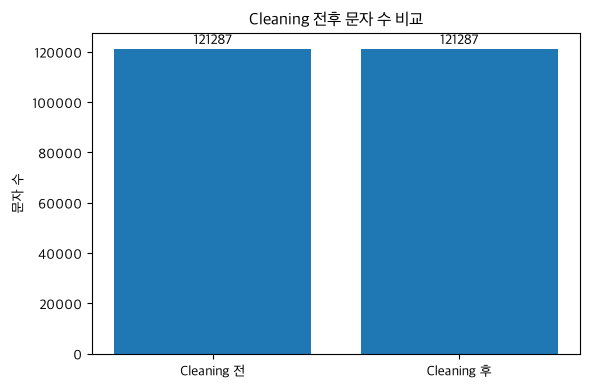

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(136)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# import re
# import pandas as pd
# import matplotlib.pyplot as plt
#
# # 기존 Cleaning에서 제거하는 제어문자
# REMOVE_CHARS = (
#     set(range(0x00, 0x09))
#     | {0x0B, 0x0C, 0x7F, 0x200B, 0xFEFF}
#     | set(range(0x0E, 0x20))
# )
#
# def clean_control_chars(text):
#     return "".join(
#         char for char in text
#         if ord(char) not in REMOVE_CHARS
#     )
#
# # 대표 HWP Body 기준 비교
# cleaned_text = clean_control_chars(raw_text)
#
# removed_chars = [
#     char for char in raw_text
#     if ord(char) in REMOVE_CHARS
# ]
#
# comparison = pd.DataFrame({
#     "구분": ["Cleaning 전", "Cleaning 후"],
#     "문자 수": [len(raw_text), len(cleaned_text)]
# })
#
# display(comparison)
#
# print(f"제거된 문자 수: {len(removed_chars):,}개")
# print(f"문자 보존 비율: {len(cleaned_text) / len(raw_text) * 100:.2f}%")
#
# # 시각화
# fig, ax = plt.subplots(figsize=(6, 4))
#
# bars = ax.bar(
#     comparison["구분"],
#     comparison["문자 수"]
# )
#
# ax.bar_label(bars, fmt="%.0f")
# ax.set_title("Cleaning 전후 문자 수 비교")
# ax.set_ylabel("문자 수")
#
# plt.tight_layout()
# plt.show()

#### 분석 결과 및 처리 방법

대표 HWP Body(121,287자)에 제어문자 제거 규칙을 적용한 결과,
제거 대상 문자는 발견되지 않았으며 전후 문자 수는 동일했다.

**처리 방법 및 선택 이유**
- 일반 문장부호와 표 구분 기호는 일괄 삭제하지 않는다.
- 불필요한 제어문자만 선택적으로 제거한다.
- 문자 깨짐이 의심되는 부분은 원본 근거를 확인한 후 복구한다.

이번 결과는 대표문서의 제어문자 검사에 한정되며,
전체 문서의 Cleaning 성공률이나 원문 보존율을 의미하지 않는다.

## 5. 목차 및 문서 구조 분석

### 5.1 분석 목적

RFP 문서의 목차는 본문 내용을 탐색하기 위한 목차와
제안서 작성에 필요한 항목을 안내하는 목차로 구분할 수 있다.

목차를 일괄 삭제하면 중요한 작성 지침이 손실될 수 있으므로,
기존 전처리에서 목차를 어떻게 처리했는지 확인한다.

### 기존 전처리 방식

| 목차 유형 | 처리 방식 | 선택 이유 |
|---|---|---|
| 탐색용 목차 | 검증된 구간만 검색 입력에서 제외 | 본문과 중복되는 검색 결과 방지 |
| 제안서 작성용 목차 | 원본 근거로 복원하여 보존 | 제안서 필수 작성 항목 유지 |
| PDF 목차 | 검증된 구간을 `toc` Element로 분리 | 본문과 목차의 구조적 역할 구분 |

**주의사항**
- 목차의 원문 보존과 검색 대상 제외는 서로 다른 처리이다.
- HWP 목차 전체가 자동으로 분리된 것은 아니다.
- 기존 v12에서 검증된 처리 결과만 분석한다.

,문서 형식,toc Element 수,전체 문서 수,toc Element 확인 문서 수
0,HWP,0,94,0
1,PDF,56,4,3


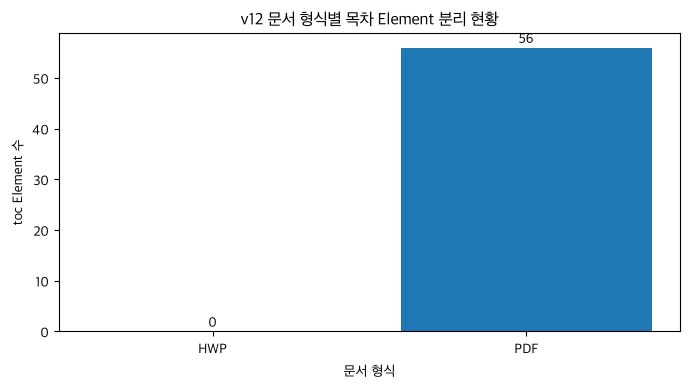

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(139)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# import pandas as pd
# import matplotlib.pyplot as plt
#
# # Codex가 v12 최종 산출물에서 확인한 집계
# toc_summary = pd.DataFrame({
#     "문서 형식": ["HWP", "PDF"],
#     "toc Element 수": [0, 56],
#     "전체 문서 수": [94, 4],
#     "toc Element 확인 문서 수": [0, 3]
# })
#
# display(toc_summary)
#
# # 시각화
# fig, ax = plt.subplots(figsize=(7, 4))
#
# bars = ax.bar(
#     toc_summary["문서 형식"],
#     toc_summary["toc Element 수"]
# )
#
# ax.bar_label(bars)
#
# ax.set_title("v12 문서 형식별 목차 Element 분리 현황")
# ax.set_xlabel("문서 형식")
# ax.set_ylabel("toc Element 수")
#
# plt.tight_layout()
# plt.show()

#### 분석 범위

본 분석은 v13에 승계된 목차 구조화 결과를 대상으로 한다.

PDF 3개 문서에서 총 56개의 `toc` Element가 확인되었으며,
HWP에서는 별도 `toc` Element가 확인되지 않았다.

단, 이는 목차가 실제로 존재하는 문서의 수나
전체 목차 탐지 정확도를 의미하지 않는다.

목차의 검색 제외, 원문 보존, Element 분리는
서로 다른 처리 과정이므로 구분하여 해석한다.

## 6. 요구사항 ID 분석

### 6.1 분석 목적

RFP 문서에는 SFR(기능 요구사항), SER(보안 요구사항) 등
다양한 요구사항 ID가 포함되어 있다.

요구사항 ID는 문서의 내용을 식별하고,
질문과 관련된 요구사항을 검색하는 데 중요한 정보이다.

따라서 v12 최종 데이터를 기준으로 다음 항목을 분석한다.

- 요구사항 ID 유형별 분포
- 요구사항 ID가 포함된 Record 수
- 동일 ID가 반복되는 원인과 중복 처리 기준

### 기존 전처리 방식

대문자 접두어와 숫자로 구성된 요구사항 ID를 정규식으로 추출하였다.

이후 요구사항 목록과 상세 내용, 여러 페이지에 걸친 요구사항의
연결 관계를 보완하였다.

동일한 ID가 여러 번 등장하더라도 실제 중복 데이터라고
단정하지 않고 문서 내 소속과 내용을 함께 검토하였다.

,요구사항 유형,등장 횟수
0,SFR,1339
1,PMR,981
2,SER,798
3,COR,678
4,DAR,610
5,PSR,530
6,QUR,426
7,TER,354
8,ECR,353
9,PER,351


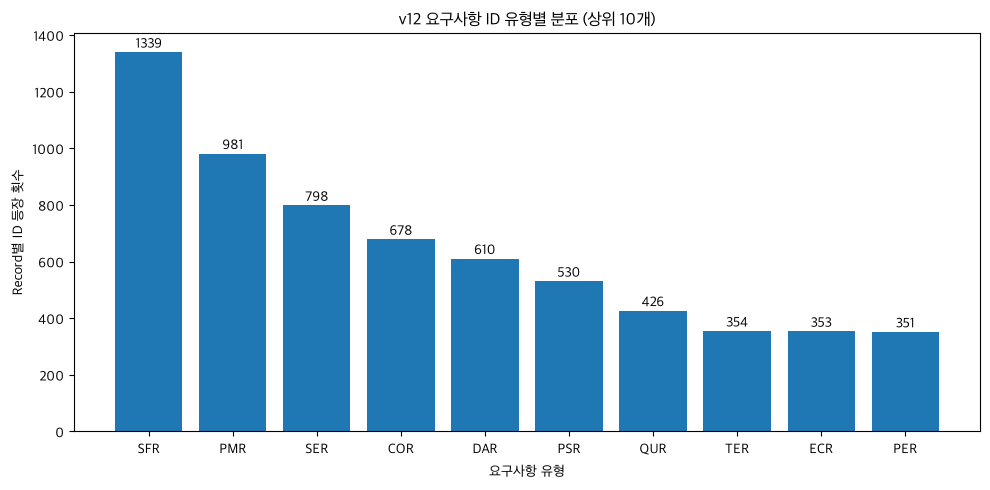

요구사항 ID 포함 Record: 7,337개
요구사항 ID 등장 횟수 합계: 7,438회
고유 (문서, ID) 조합: 5,319개


In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(142)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# import pandas as pd
# import matplotlib.pyplot as plt
#
# # v12 최종 Record에서 확인된 요구사항 ID 유형별 등장 횟수
# requirement_counts = {
#     "SFR": 1339,
#     "PMR": 981,
#     "SER": 798,
#     "COR": 678,
#     "DAR": 610,
#     "PSR": 530,
#     "QUR": 426,
#     "TER": 354,
#     "ECR": 353,
#     "PER": 351
# }
#
# df_requirements = pd.DataFrame(
#     requirement_counts.items(),
#     columns=["요구사항 유형", "등장 횟수"]
# )
#
# display(df_requirements)
#
# fig, ax = plt.subplots(figsize=(10, 5))
#
# bars = ax.bar(
#     df_requirements["요구사항 유형"],
#     df_requirements["등장 횟수"]
# )
#
# ax.bar_label(bars)
#
# ax.set_title("v12 요구사항 ID 유형별 분포 (상위 10개)")
# ax.set_xlabel("요구사항 유형")
# ax.set_ylabel("Record별 ID 등장 횟수")
#
# plt.tight_layout()
# plt.show()
#
# print("요구사항 ID 포함 Record: 7,337개")
# print("요구사항 ID 등장 횟수 합계: 7,438회")
# print("고유 (문서, ID) 조합: 5,319개")

### 6.2 분석 결과 및 처리 방식

#### 주요 발견점

- v12에서 요구사항 ID가 포함된 Record는 7,337개이다.
- Record별 요구사항 ID 등장 횟수는 총 7,438회이다.
- 고유한 (문서, 요구사항 ID) 조합은 5,319개이다.
- 주요 유형 중 SFR이 1,339회로 가장 많이 등장하였다.

#### 처리 방식 및 선택 이유

**1. 정규식 기반 ID 추출**

문서에 사용된 다양한 요구사항 ID 형식을 처리하기 위해
특정 유형만 지정하지 않고 대문자 접두어와 숫자 패턴을 사용하였다.

**2. 동일 ID의 반복 허용**

요구사항 ID는 목록과 상세 설명에서 반복될 수 있다.
따라서 동일 ID를 단순 중복으로 판단하여 삭제하지 않았다.

**3. 요구사항 연결 관계 보완**

하나의 요구사항이 여러 페이지나 Record에 나뉘어 있는 경우
원문 근거가 확인된 범위에서 소속 관계를 보완하였다.

#### 분석 한계

요구사항 ID 등장 횟수는 실제 독립 요구사항 수와 다르다.

이번 분석은 저장된 v12 집계 결과를 기반으로 하며,
모든 요구사항의 원본 대비 완전성을 검증한 것은 아니다.

### 6.3 요구사항 ID 유형별 분포 분석

#### 분석 목적

RFP 문서에 포함된 요구사항 ID의 유형별 분포를 분석하여
주요 요구사항 유형과 데이터의 특징을 파악한다.

#### 분석 방법

- v13 최종 일반 Record 23,766개를 분석한다.
- 검증용 자식 Record 46개는 중복 집계를 방지하기 위해 제외한다.
- 요구사항 ID의 접두어(SFR, SER, DAR 등)를 추출한다.
- 유형별 등장 횟수를 시각화한다.

#### 분석 시 주의사항

요구사항 ID는 목록과 상세 설명에서 반복될 수 있으므로,
등장 횟수를 실제 독립 요구사항 수로 해석하지 않는다.

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(145)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# import json
# import pandas as pd
# from pathlib import Path
#
# # v13 데이터 경로
# V13_DIR = Path(os.environ.get("RFP_V13_DIR", str(PROJECT_DIR / "data/RFP_Preprocessing_Final_v13")))
#
# assert V13_DIR.is_dir(), "v13 데이터 폴더를 확인하세요."
#
# # 일반 Record와 검증용 자식 Record 구분
# with (V13_DIR / "final_records.jsonl").open(encoding="utf-8") as f:
#     record_rows = [json.loads(line) for line in f if line.strip()]
#
# df_records_all = pd.DataFrame(record_rows)
#
# is_child = df_records_all["verification_child"].fillna(False).astype(bool)
#
# df_records = df_records_all.loc[~is_child].copy()
# df_verification = df_records_all.loc[is_child].copy()
#
# # 집계 대상 확인
# assert len(df_records_all) == 23812
# assert len(df_records) == 23766
# assert len(df_verification) == 46
#
# print("✅ v13 데이터 로딩 완료")
# print(f"일반 Record: {len(df_records):,}개")
# print(f"검증용 자식 Record: {len(df_verification):,}개")

✅ v13 데이터 로딩 완료
일반 Record: 23,766개
검증용 자식 Record: 46개


,요구사항 유형,등장 횟수
0,SFR,1339
1,PMR,981
2,SER,798
3,COR,678
4,DAR,610
5,PSR,530
6,QUR,426
7,TER,354
8,ECR,353
9,PER,351


ID 포함 일반 Record: 7,337개
ID 유형 분석에 포함된 등장 횟수: 7,438회


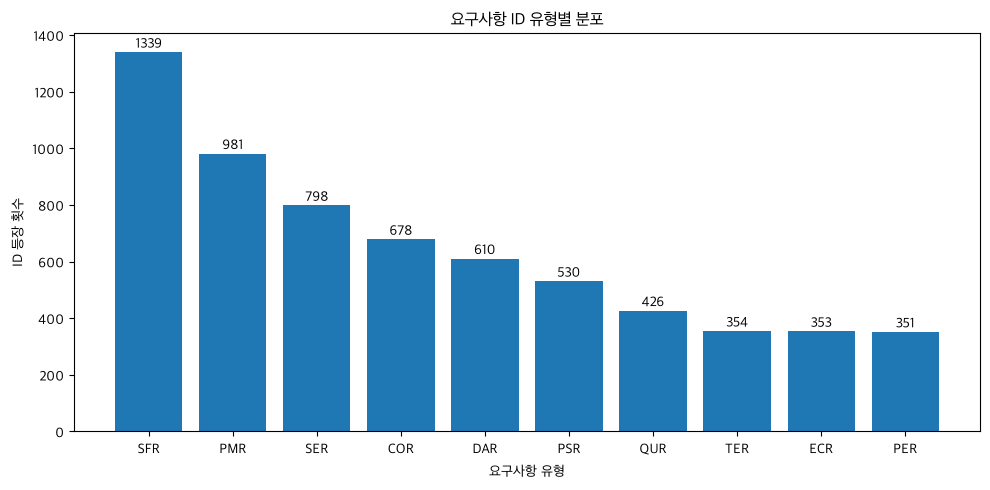

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(146)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# from collections import Counter
# import matplotlib.pyplot as plt
# import pandas as pd
# import re
#
# # v13 일반 Record의 요구사항 ID 집계
# id_counter = Counter()
# records_with_id = 0
#
# for ids in df_records["requirement_ids"]:
#     if not isinstance(ids, list) or not ids:
#         continue
#
#     records_with_id += 1
#
#     for rid in ids:
#         match = re.match(r"^([A-Z]{2,6})\s*[-－]", str(rid).strip())
#
#         if match:
#             id_counter[match.group(1)] += 1
#
# # 상위 10개 유형
# df_id_distribution = pd.DataFrame(
#     id_counter.most_common(10),
#     columns=["요구사항 유형", "등장 횟수"]
# )
#
# display(df_id_distribution)
#
# print(f"ID 포함 일반 Record: {records_with_id:,}개")
# print(f"ID 유형 분석에 포함된 등장 횟수: {sum(id_counter.values()):,}회")
#
# # 시각화
# fig, ax = plt.subplots(figsize=(10, 5))
#
# bars = ax.bar(
#     df_id_distribution["요구사항 유형"],
#     df_id_distribution["등장 횟수"]
# )
#
# ax.bar_label(bars)
# ax.set_title("요구사항 ID 유형별 분포")
# ax.set_xlabel("요구사항 유형")
# ax.set_ylabel("ID 등장 횟수")
#
# plt.tight_layout()
# plt.show()

#### 분석 결과 및 해석

전처리 후 일반 Record 23,766개에서 요구사항 ID를 분석한 결과,
7,337개 Record에 요구사항 ID가 포함되어 있었다.

요구사항 ID는 총 7,438회 등장했으며,
SFR(1,339회), PMR(981회), SER(798회) 순으로 많이 나타났다.

이는 RFP 문서에 다양한 유형의 요구사항이 포함되어 있으며,
기능 요구사항(SFR)의 등장 빈도가 가장 높다는 것을 보여준다.

#### 전처리 방법 및 선택 이유

초기 전처리에서는 정규식을 이용하여 요구사항 ID를 추출하였다.

이후 요구사항 목록과 상세 설명에서 동일 ID가 반복되거나,
여러 페이지에 걸쳐 요구사항이 작성되는 문제가 확인되었다.

이에 따라 요구사항 ID를 단순히 중복 제거하지 않고,
문서 내 위치와 목록·상세 내용의 관계를 고려하여
요구사항 소속 정보를 보완하였다.

**선택 이유**

동일 ID가 여러 번 등장하더라도 실제 중복 데이터가 아닐 수 있으며,
단순 삭제할 경우 요구사항의 상세 내용이나 출처 정보가
손실될 가능성이 있기 때문이다.

※ ID 등장 횟수는 실제 독립 요구사항 수와 다르다.

### 6.4 요구사항 소속 정보 개선 전·후 비교

#### 분석 목적

요구사항 ID가 텍스트에 등장하더라도 해당 데이터가
올바른 요구사항에 연결되어 있다는 의미는 아니다.

실제 전처리 과정에서 일부 Element와 Chunk의
요구사항 소속 정보가 부정확한 사례가 발견되었다.

따라서 원문은 유지하면서 소속 정보를 보완한 결과를 분석한다.

#### 분석 방법

- 개선 전·후 Chunk의 요구사항 소속 키 비교
- 요구사항 소속 키가 없는 Chunk 현황 확인
- 원문을 수정하지 않고 메타데이터를 보완한 이유 분석

※ 소속 키가 없는 Chunk를 요구사항이 없는 데이터로 단정하지 않는다.

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(149)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# # 최종 전처리 Chunk 데이터 불러오기
# with (V13_DIR / "final_chunks.jsonl").open(encoding="utf-8") as f:
#     chunk_rows = [json.loads(line) for line in f if line.strip()]
#
# assert len(chunk_rows) == 18997
#
# print(f"Chunk 데이터 로딩 완료: {len(chunk_rows):,}개")

Chunk 데이터 로딩 완료: 18,997개


,구분,Chunk 수,비율(%)
0,소속 키 있음,5834,30.71
1,소속 키 없음,13163,69.29


,요구사항 키,개선 전,개선 후,변화량
0,ECR-001,46,47,1
1,DAR-04,7,8,1
2,소속 키 없음,13165,13163,-2


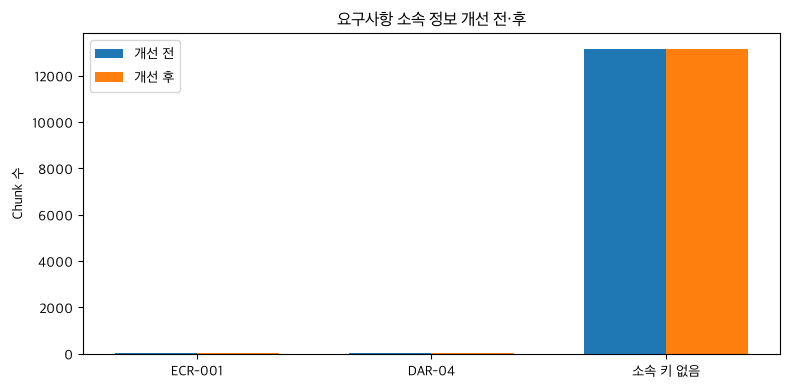

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(150)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# from collections import Counter
# import pandas as pd
# import matplotlib.pyplot as plt
#
# # 최종 전처리 데이터의 Chunk 소속 정보
# chunk_key_counts = Counter(
#     chunk.get("requirement_key")
#     for chunk in chunk_rows
# )
#
# total_chunks = len(chunk_rows)
# null_count = chunk_key_counts[None]
# assigned_count = total_chunks - null_count
#
# # 소속 키 현황
# df_assignment = pd.DataFrame({
#     "구분": ["소속 키 있음", "소속 키 없음"],
#     "Chunk 수": [assigned_count, null_count]
# })
#
# df_assignment["비율(%)"] = (
#     df_assignment["Chunk 수"] / total_chunks * 100
# ).round(2)
#
# display(df_assignment)
#
# # 개선 전후 비교
# df_changes = pd.DataFrame({
#     "요구사항 키": ["ECR-001", "DAR-04", "소속 키 없음"],
#     "개선 전": [46, 7, 13165],
#     "개선 후": [
#         chunk_key_counts["ECR-001"],
#         chunk_key_counts["DAR-04"],
#         null_count
#     ]
# })
#
# df_changes["변화량"] = (
#     df_changes["개선 후"] - df_changes["개선 전"]
# )
#
# display(df_changes)
#
# # 개선 전후 비교 그래프
# fig, ax = plt.subplots(figsize=(8, 4))
#
# x = range(len(df_changes))
# width = 0.35
#
# ax.bar(
#     [i - width/2 for i in x],
#     df_changes["개선 전"],
#     width,
#     label="개선 전"
# )
#
# ax.bar(
#     [i + width/2 for i in x],
#     df_changes["개선 후"],
#     width,
#     label="개선 후"
# )
#
# ax.set_xticks(list(x))
# ax.set_xticklabels(df_changes["요구사항 키"])
# ax.set_title("요구사항 소속 정보 개선 전·후")
# ax.set_ylabel("Chunk 수")
# ax.legend()
#
# plt.tight_layout()
# plt.show()
#
# assert total_chunks == 18997
# assert chunk_key_counts["ECR-001"] == 47
# assert chunk_key_counts["DAR-04"] == 8
# assert null_count == 13163

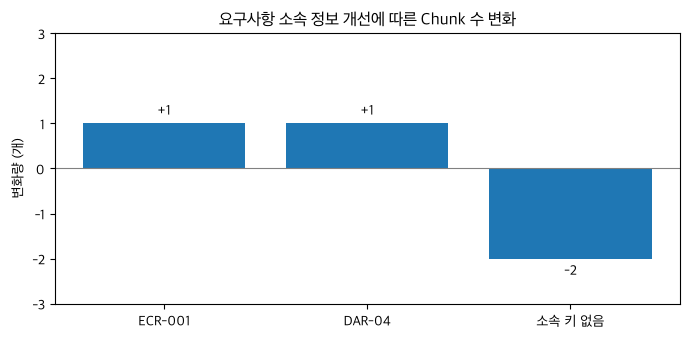

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(151)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# # 개선 전후 변화량 시각화
# fig, ax = plt.subplots(figsize=(7, 3.5))
#
# bars = ax.bar(
#     df_changes["요구사항 키"],
#     df_changes["변화량"]
# )
#
# ax.bar_label(bars, fmt="%+.0f", padding=3)
#
# ax.axhline(0, color="gray", linewidth=0.8)
# ax.set_title("요구사항 소속 정보 개선에 따른 Chunk 수 변화")
# ax.set_ylabel("변화량 (개)")
# ax.set_ylim(-3, 3)
#
# plt.tight_layout()
# plt.show()

#### 분석 결과 및 처리 방식

전체 Chunk 18,997개 중 5,834개(30.71%)에 요구사항 소속 키가 있으며,
13,163개(69.29%)는 소속 키가 없는 상태이다.

> ECR-001 — 장비 구성 요구사항
사업 수행에 필요한 장비나 시스템 구성에 관한 요구사항을 의미 (예를 들어 서버, 네트워크 장비, 시스템 구성 등에 관한 내용)

> DAR-04 — 데이터 요구사항
데이터 구축, 이관, 변환, 정합성 등에 관한 요구사항을 의미

소속 정보 개선 과정에서 다음 변경이 확인되었다.

- ECR-001 : 46개 → 47개
- DAR-04: 7개 → 8개
- 소속 키 없음: 13,165개 → 13,163개

#### 발견한 문제

요구사항 ID가 텍스트에 포함되어 있더라도,
해당 Chunk가 올바른 요구사항에 연결되지 않을 수 있다.

#### 개선 방법 및 선택 이유

원본 내용의 오류가 아니라 요구사항 소속 정보의 문제이므로,
본문을 다시 추출하거나 수정하는 대신 검증된 근거를 바탕으로
연결 메타데이터를 보완하였다.

이를 통해 원문을 유지하면서 두 Chunk의 요구사항 소속 키를
추가로 연결하였다.

#### 한계

소속 키가 없는 Chunk가 모두 오류인 것은 아니다.
목차, 일반 설명, 요구사항 외 문서 내용도 포함될 수 있다.

또한 이번 결과는 소속 정보 변경 내역이며,
전체 요구사항 연결 정확도가 개선되었다는 인증 결과는 아니다.

## 7. 최종 전처리 데이터 EDA

### 7.1 최종 데이터 구조 분석

#### 분석 목적

원본 RFP 문서는 전처리 과정을 거쳐 Record, Element, Chunk 구조로 정리된다.

각 데이터의 역할과 구성 비율을 분석하여
최종 검색 데이터가 어떤 형태로 만들어졌는지 확인한다.

#### 데이터 구조

| 구분 | 역할 |
|---|---|
| Record | 문서에서 추출·정제한 텍스트와 출처 정보를 관리하는 단위 |
| Element | 본문, 표, 목차 등 문서의 구조를 표현하는 단위 |
| Chunk | 검색과 답변의 근거로 사용할 텍스트 단위 |

#### 분석 방법

- 일반 Record와 검증용 자식 Record 구분
- Element 유형별 분포 확인
- 전체 Chunk와 검색 대상 Chunk 수 구분
- 최종 데이터 구조 시각화

※ Record, Element, Chunk는 서로 다른 데이터 단위이므로
개수 차이를 데이터 손실이나 증가율로 해석하지 않는다.

,Element 유형,개수
0,table,14030
1,paragraph,11935
2,toc,56
3,image_text,24


,데이터 유형,개수
0,일반 Record,23766
1,검증용 자식 Record,46
2,Element,26045
3,Chunk,18997


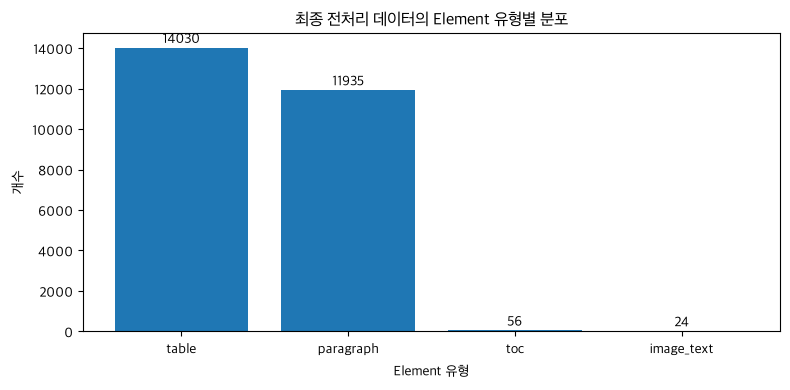

최종 데이터 구조 검증 완료


In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(154)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# from collections import Counter
# import json
# import pandas as pd
# import matplotlib.pyplot as plt
#
# # 최종 Element 데이터 로딩
# with (V13_DIR / "final_elements.jsonl").open(encoding="utf-8") as f:
#     element_rows = [json.loads(line) for line in f if line.strip()]
#
# # Element 유형별 집계
# element_counts = Counter(
#     element.get("kind", "unknown")
#     for element in element_rows
# )
#
# df_element_types = pd.DataFrame(
#     element_counts.most_common(),
#     columns=["Element 유형", "개수"]
# )
#
# display(df_element_types)
#
# # 데이터 전체 구성
# df_structure = pd.DataFrame({
#     "데이터 유형": [
#         "일반 Record",
#         "검증용 자식 Record",
#         "Element",
#         "Chunk"
#     ],
#     "개수": [
#         len(df_records),
#         len(df_verification),
#         len(element_rows),
#         len(chunk_rows)
#     ]
# })
#
# display(df_structure)
#
# # Element 유형별 시각화
# fig, ax = plt.subplots(figsize=(8, 4))
#
# bars = ax.bar(
#     df_element_types["Element 유형"],
#     df_element_types["개수"]
# )
#
# ax.bar_label(bars, fmt="%.0f")
# ax.set_title("최종 전처리 데이터의 Element 유형별 분포")
# ax.set_xlabel("Element 유형")
# ax.set_ylabel("개수")
#
# plt.tight_layout()
# plt.show()
#
# # 데이터 개수 검증
# assert len(df_records) == 23766
# assert len(df_verification) == 46
# assert len(element_rows) == 26045
# assert len(chunk_rows) == 18997
#
# print("최종 데이터 구조 검증 완료")

#### 분석 결과 및 해석

최종 전처리 데이터의 Element 26,045개를 분석한 결과,
다음과 같은 구조가 확인되었다.

| Element 유형 | 개수 | 비율 |
|---|---:|---:|
| table | 14,030 | 53.87% |
| paragraph | 11,935 | 45.82% |
| toc | 56 | 0.22% |
| image_text | 24 | 0.09% |

#### 주요 발견점

표(table)가 전체 Element의 약 53.87%로 가장 높은 비중을 차지했다.

이는 RFP 문서의 요구사항과 세부 조건을 분석할 때
표 구조를 중요하게 고려해야 한다는 근거가 된다.

#### 전처리 방법 및 선택 이유

표를 단순한 일반 문장으로 취급하면 행·열 관계나
요구사항과 상세 내용의 연결이 손실될 수 있다.

따라서 기존 전처리에서는 표를 별도 Element로 관리하고,
원본 근거가 확인된 경우에는 셀 구조와 병합 정보를 보완하였다.

#### 분석 한계

Element 개수는 실제 텍스트 분량과 다르다.
또한 모든 표의 원본 셀 구조가 완전히 복원된 것은 아니다.

### 7.2 문서별 텍스트 분량 분석

#### 분석 목적

RFP 문서는 사업 규모와 문서 구성에 따라 텍스트 분량이 다를 수 있다.

문서별 텍스트 길이 분포와 이상치를 확인하여
데이터의 편차를 분석한다.

#### 분석 방법

- 일반 Record의 `clean_text` 길이 측정
- 문서별 문자 수 합계 계산
- 히스토그램과 박스플롯을 이용한 분포 확인

검증용 자식 Record는 기존 내용의 일부를 재사용하므로
일반 문서 분량 집계에서 제외한다.

※ 본 분석은 전처리 후 Record의 문자 수 합계이며,
원본 파일의 정확한 전체 문자 수와 동일하지 않을 수 있다.

,문서별 문자 수
count,98.0
mean,85442.6
std,38536.7
min,48751.0
25%,63901.0
50%,75123.5
75%,90766.5
max,284853.0


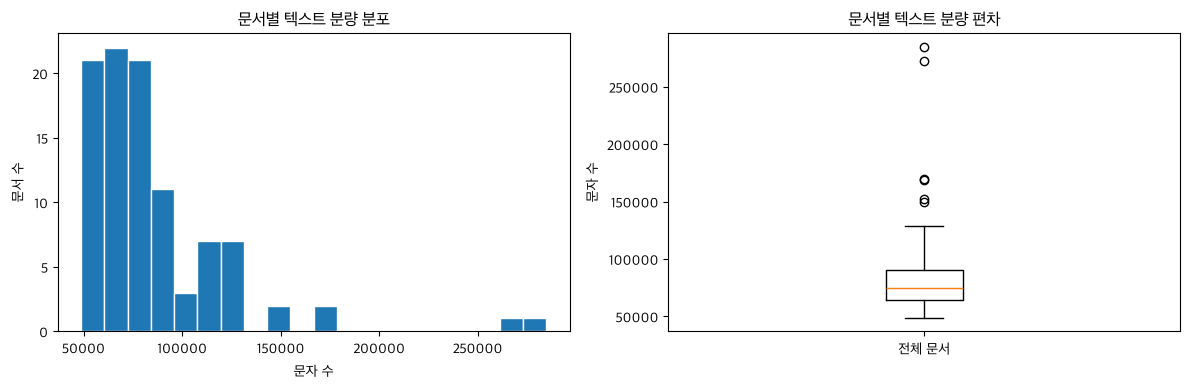

분석 문서: 98개
최소 문자 수: 48,751
최대 문자 수: 284,853


In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(157)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# import pandas as pd
# import matplotlib.pyplot as plt
#
# # 일반 Record 기준 텍스트 길이
# df_doc_lengths = df_records[["doc_id", "clean_text"]].copy()
#
# df_doc_lengths["문자 수"] = (
#     df_doc_lengths["clean_text"]
#     .fillna("")
#     .astype(str)
#     .str.len()
# )
#
# # 문서별 합계
# df_doc_lengths = (
#     df_doc_lengths.groupby("doc_id", as_index=False)["문자 수"]
#     .sum()
# )
#
# assert len(df_doc_lengths) == 98
#
# display(df_doc_lengths["문자 수"].describe().round(1).to_frame("문서별 문자 수"))
#
# # 시각화
# fig, axes = plt.subplots(1, 2, figsize=(12, 4))
#
# axes[0].hist(df_doc_lengths["문자 수"], bins=20, edgecolor="white")
# axes[0].set_title("문서별 텍스트 분량 분포")
# axes[0].set_xlabel("문자 수")
# axes[0].set_ylabel("문서 수")
#
# axes[1].boxplot(df_doc_lengths["문자 수"])
# axes[1].set_title("문서별 텍스트 분량 편차")
# axes[1].set_ylabel("문자 수")
# axes[1].set_xticks([1], ["전체 문서"])
#
# plt.tight_layout()
# plt.show()
#
# print(f"분석 문서: {len(df_doc_lengths)}개")
# print(f"최소 문자 수: {df_doc_lengths['문자 수'].min():,}")
# print(f"최대 문자 수: {df_doc_lengths['문자 수'].max():,}")

#### 분석 결과 및 해석

전체 98개 문서의 전처리 후 텍스트 분량을 분석하였다.

| 항목 | 문자 수 |
|---|---:|
| 평균 | 85,443자 |
| 중앙값 | 75,124자 |
| 최소 | 48,751자 |
| 최대 | 284,853자 |
| 표준편차 | 38,537자 |

#### 주요 발견점

- 문서별 텍스트 분량은 약 4.9만~28.5만 자로 편차가 크다.
- 평균이 중앙값보다 높아 일부 대용량 문서가 평균을 높이고 있다.
- 히스토그램에서 대부분의 문서는 약 5만~10만 자 구간에 분포한다.
- 박스플롯에서 일부 문서가 상단 이상치로 확인되었다.

#### 전처리 및 검색 설계 시 고려사항

문서별 분량 차이가 크므로 특정 대용량 문서의 내용이
검색 데이터에 상대적으로 많이 포함될 가능성이 있다.

따라서 문서별 분량과 검색 결과의 편중 여부를 별도로 확인할 필요가 있다.

단, 문서 분량이 크다는 이유만으로
해당 문서를 제거하거나 중요도를 낮추지는 않는다.

※ 본 분석은 일반 Record의 clean_text 문자 수를 문서별로 합산한 결과이며,
원본 문서의 실제 전체 문자 수나 검색 성능을 의미하지 않는다.

### 7.3 메타데이터 구조 및 품질 분석

#### 분석 목적

RAG 시스템은 검색된 텍스트뿐 아니라 해당 내용의
출처와 문서 내 위치를 함께 관리해야 한다.

원본 문서에서 추출한 데이터가 Record, Element, Chunk로
변환되는 과정에서 출처·문서 구조·요구사항 소속 정보가
어떻게 관리되는지 확인한다.

#### 분석 항목

- 문서 출처 및 위치 정보
- 제목 경로와 Element 유형
- 요구사항 ID 및 소속 정보
- Record와 Element의 연결 관계

#### 분석 시 주의사항

메타데이터가 비어 있다고 해서 모두 오류인 것은 아니다.
문서 유형이나 데이터 역할에 따라 해당 정보가
필요하지 않을 수도 있다.

따라서 필드의 존재 여부와 실제 정확성 검증을 구분한다.

,메타데이터 항목,보유 Element 수,보유 비율(%)
0,문서 ID (최상위 직접 필드),0,0.00
1,Record 연결,26045,100.00
2,제목 경로,14189,54.48
3,요구사항 ID,9733,37.37
4,위치 정보,5194,19.94


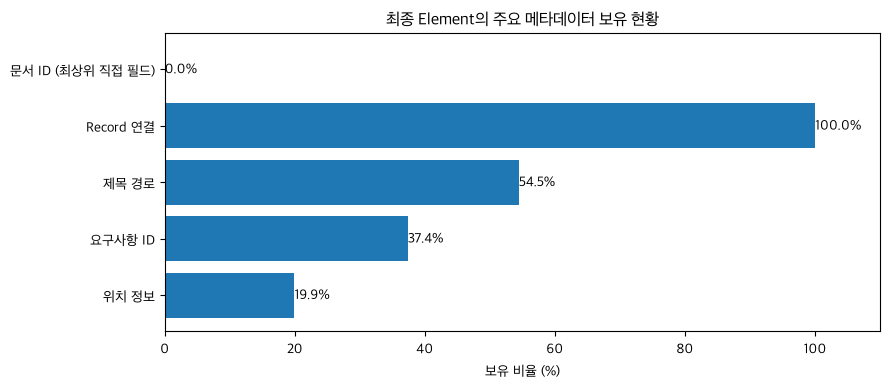

In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(160)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# import pandas as pd
# import matplotlib.pyplot as plt
#
# # Element 메타데이터 분석
# metadata_stats = []
#
# for element in element_rows:
#     location = element.get("location") or {}
#     supplier = location.get("supplier_metadata") or {}
#
#     metadata_stats.append({
#         "문서 ID (최상위 직접 필드)": bool(element.get("doc_id")),
#         "Record 연결": bool(location.get("record_id")),
#         "제목 경로": bool(element.get("section_path") or location.get("section_path")),
#         "요구사항 ID": bool(supplier.get("requirement_ids")),
#         "위치 정보": bool(location.get("page") or location.get("source_span"))
#     })
#
# df_metadata = pd.DataFrame(metadata_stats)
#
# df_metadata_summary = pd.DataFrame({
#     "메타데이터 항목": df_metadata.columns,
#     "보유 Element 수": df_metadata.sum().values
# })
#
# df_metadata_summary["보유 비율(%)"] = (
#     df_metadata_summary["보유 Element 수"] / len(element_rows) * 100
# ).round(2)
#
# display(df_metadata_summary)
#
# # 시각화
# fig, ax = plt.subplots(figsize=(9, 4))
#
# bars = ax.barh(
#     df_metadata_summary["메타데이터 항목"],
#     df_metadata_summary["보유 비율(%)"]
# )
#
# ax.bar_label(bars, fmt="%.1f%%")
# ax.invert_yaxis()
# ax.set_xlim(0, 110)
# ax.set_title("최종 Element의 주요 메타데이터 보유 현황")
# ax.set_xlabel("보유 비율 (%)")
#
# plt.tight_layout()
# plt.show()

### 메타데이터 보존 및 연결

**발견한 문제**

문서가 Record, Element, Chunk로 변환되면서
원본 위치와 요구사항 소속 관계가 잘못 연결되거나
불명확해질 수 있다.

**선택한 방법**

문서 ID, 원본 위치, 제목 경로, 요구사항 ID 등
출처와 구조 정보를 메타데이터로 관리하고,
검증된 원본 근거를 바탕으로 연결 관계를 보완하였다.

**선택 이유**

검색된 텍스트가 어떤 문서와 요구사항에서 유래했는지
추적할 수 있어야 답변의 근거를 확인할 수 있기 때문이다.

**검증 및 한계**

일부 Element와 Chunk의 소속 정보를 검증하여 수정했으나,
전체 메타데이터의 정확성이 인증된 것은 아니다.

**그래프 해석 보완:** 문서 ID의 0%는 Element **최상위 `doc_id` 필드 직접 보유율**입니다. 문서 출처를 조회할 수 없다는 뜻이 아닙니다. v13 저장 파일에서 `location.record_id` → Record의 `doc_id`로 연결하면 26,045/26,045개 Element(100%)에서 문서 ID를 조회할 수 있습니다. 직접 필드 존재, 간접 조회 가능성, 원본 대응의 실제 정확성은 서로 다릅니다. 이 확인은 저장 JSONL의 참조 검사이며 원본 보존 인증이 아닙니다.

## 8. 데이터 품질 및 검증 현황 EDA

### 8.1 원문 보존 검증 현황

#### 분석 목적

전처리 과정에서 원본 문서의 정보가 누락되거나
잘못 변경되지 않았는지 확인하는 것은 중요하다.

최종 전처리 데이터의 원문 보존 검증 상태를 분석하여
확인이 완료된 범위와 추가 검증이 필요한 범위를 파악한다.

#### 분석 기준

- 원문 단위별 검증 결과를 사용한다.
- 검증 완료(PASS)와 미검증(UNVERIFIED)을 구분한다.
- 검증되지 않은 데이터를 실제 오류나 누락으로 단정하지 않는다.
- 검증 완료 비율을 전체 원문 보존율로 해석하지 않는다.

,검증 상태,원문 단위 수,비율(%)
0,PASS,218764,71.57
1,UNVERIFIED,86887,28.43


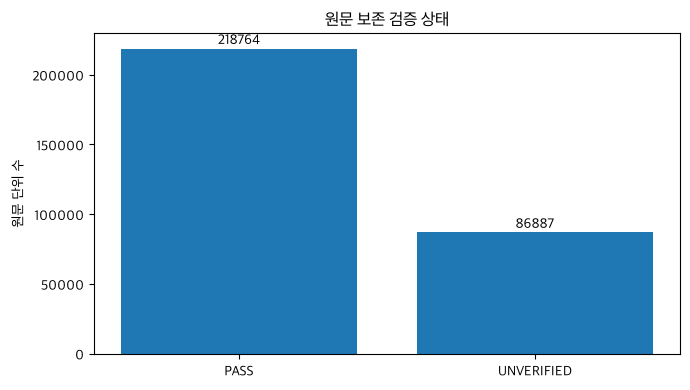

검증 대상 원문 단위: 305,651개
검증 완료 비율: 71.57%


In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(163)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# import pandas as pd
# import matplotlib.pyplot as plt
#
# # v13 manifest의 저장된 공식 검증 집계 (v12 기준이 아님)
# total_sources = 305651
# verified_sources = 218764
# unverified_sources = total_sources - verified_sources
#
# df_preservation = pd.DataFrame({
#     "검증 상태": ["PASS", "UNVERIFIED"],
#     "원문 단위 수": [verified_sources, unverified_sources]
# })
#
# df_preservation["비율(%)"] = (
#     df_preservation["원문 단위 수"] / total_sources * 100
# ).round(2)
#
# display(df_preservation)
#
# fig, ax = plt.subplots(figsize=(7, 4))
#
# bars = ax.bar(
#     df_preservation["검증 상태"],
#     df_preservation["원문 단위 수"]
# )
#
# ax.bar_label(bars, fmt="%.0f")
# ax.set_title("원문 보존 검증 상태")
# ax.set_ylabel("원문 단위 수")
#
# plt.tight_layout()
# plt.show()
#
# print(f"검증 대상 원문 단위: {total_sources:,}개")
# print(f"검증 완료 비율: {verified_sources / total_sources * 100:.2f}%")

### 8.1.1 원문 보존 검증 방법

#### 검증 목적

전처리가 정상적으로 완료되더라도 원본 내용이
최종 검색 데이터까지 정확하게 전달되었다고 볼 수는 없다.

따라서 원본과 최종 데이터 사이의 연결 관계를 확인하였다.

**원본 문서 → Record → Element → Chunk**

| 검증 단계 | 확인 내용 |
|---|---|
| 원본 → Record | 원본 위치와 추출 텍스트가 대응하는가? |
| Record → Element | 구조 변환 과정에서 내용과 소속이 유지되는가? |
| Element → Chunk | 검색에 필요한 텍스트가 올바른 근거로 전달되는가? |

#### 검증 방법을 선택한 이유

단순히 문서가 정상적으로 파싱되었다는 사실만으로는
내용 누락이나 잘못된 요구사항 연결을 발견하기 어렵다.

따라서 텍스트뿐 아니라 원본 위치와 데이터 간 연결 관계를
함께 확인하는 방식을 사용하였다.

#### 검증 결과 및 한계

- 전체 원문 단위 305,651개 중 218,764개(71.57%) PASS
- 86,887개(28.43%)는 UNVERIFIED
- 미검증은 실제 오류나 누락을 의미하지 않음
- 전체 원문의 완전한 보존 인증은 아직 완료되지 않음

※ 공식 검증 결과에 반영되지 않은 별도 인증 후보는
위 PASS 수치에 포함하지 않는다.

위 PASS 수치는 **v13 공식 저장 집계**입니다. v12 Team의 PASS 217,866개·UNVERIFIED 87,785개·71.28%와 구분하며 두 버전 모두 원문 단위의 실제 보존율을 의미하지 않습니다.

### 8.2 이미지 OCR 검증 현황

#### 분석 목적

RFP 문서에는 스캔 문서, 표 이미지, 화면 캡처 등
텍스트 추출이 필요한 이미지가 포함되어 있다.

OCR 실행에 성공했더라도 추출된 텍스트가
원본 이미지와 정확히 일치한다고 볼 수는 없다.

따라서 이미지별 OCR 처리 현황과
실제 전사 내용의 검증 상태를 구분하여 분석한다.

#### 분석 기준

- 이미지 자산 수와 문서 내 이미지 발생 횟수를 구분한다.
- OCR 엔진 실행 성공과 정확성 검증을 구분한다.
- 부분 범위만 검증된 전사를 전체 이미지 검증으로 해석하지 않는다.

,검증 상태,이미지 발생 수,비율(%)
0,전체 정확성 미검증,1545,98.85
1,부분 범위 검증,17,1.09
2,검증 전사,1,0.06


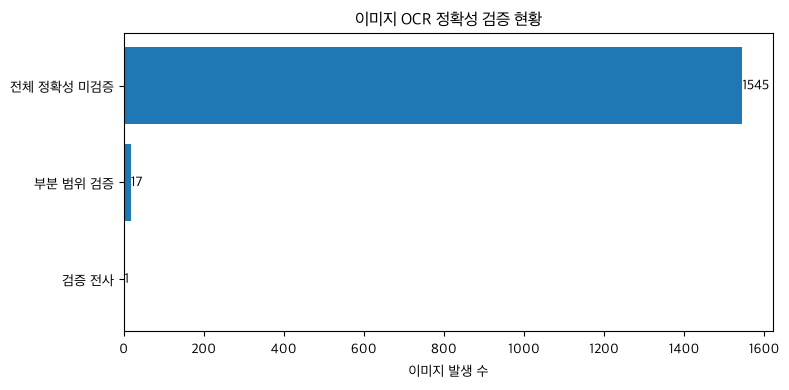

전체 이미지 발생: 1,563건
검색 반영 이미지 발생: 18건


In [ ]:
# 저장된 분석 결과를 재사용한다. 아래 과거 계산 코드는 실행하지 않는다.
show_saved_result(166)

# ── 과거 분석 코드 기록 (주석이며 실행되지 않음) ──
# import pandas as pd
# import matplotlib.pyplot as plt
#
# # 저장된 OCR 검증 결과 (이미지 발생 단위)
# ocr_status = {
#     "전체 정확성 미검증": 1545,
#     "부분 범위 검증": 17,
#     "검증 전사": 1
# }
#
# df_ocr_status = pd.DataFrame(
#     ocr_status.items(),
#     columns=["검증 상태", "이미지 발생 수"]
# )
#
# total_occurrences = df_ocr_status["이미지 발생 수"].sum()
#
# df_ocr_status["비율(%)"] = (
#     df_ocr_status["이미지 발생 수"] / total_occurrences * 100
# ).round(2)
#
# display(df_ocr_status)
#
# fig, ax = plt.subplots(figsize=(8, 4))
#
# bars = ax.barh(
#     df_ocr_status["검증 상태"],
#     df_ocr_status["이미지 발생 수"]
# )
#
# ax.bar_label(bars)
# ax.invert_yaxis()
# ax.set_title("이미지 OCR 정확성 검증 현황")
# ax.set_xlabel("이미지 발생 수")
#
# plt.tight_layout()
# plt.show()
#
# print(f"전체 이미지 발생: {total_occurrences:,}건")
# print("검색 반영 이미지 발생: 18건")

#### 분석 결과 및 해석

전체 이미지 발생 1,563건의 전사 정확성 검증 상태를 분석하였다.

| 검증 상태 | 이미지 발생 수 | 비율 |
|---|---:|---:|
| 전체 정확성 미검증 | 1,545건 | 98.85% |
| 부분 범위 검증 | 17건 | 1.09% |
| 검증 전사 | 1건 | 0.06% |

#### 주요 발견점

이미지 발생 기록의 98.85%는 전체 정확성이 검증되지 않은 상태이다.

OCR 엔진의 실행 성공과 추출된 텍스트의 정확성 검증은
서로 다른 과정이라는 점을 확인하였다.

#### 전처리 방법 및 선택 이유

OCR 결과를 검증 없이 검색 데이터에 반영하면
잘못 인식한 문자나 숫자가 답변의 근거로 사용될 수 있다.

따라서 기존 전처리에서는 이미지 및 원본 문서와 대조하여
확인된 텍스트 범위만 검색 데이터에 반영하였다.

#### 한계 및 개선 방향

- 미검증 상태를 OCR 실패나 오인식으로 단정할 수 없다.
- 부분 범위 검증은 이미지 전체의 정확성을 보장하지 않는다.
- 미검증 이미지에 대한 추가 검토가 필요하다.

※ 본 결과는 이미지 발생 단위의 검증 현황이며,
OCR 모델의 문자 인식 정확도나 성능 지표가 아니다.

## 9. EDA 종합 결론 및 전처리 의사결정

### 9.1 주요 분석 결과 및 전처리 방법

EDA를 통해 원본 문서의 중복, 파싱 과정의 정보 중복,
문자 깨짐, 표 구조 손실, 요구사항 소속 불일치 등의 문제를 확인하였다.

이에 따라 데이터를 일괄 삭제하거나 변환하기보다,
원본 정보와 문서 구조를 최대한 보존하는 방향으로 전처리를 진행하였다.

| 분석 항목 | EDA에서 발견한 특징 및 문제 | 선택한 전처리 방법과 이유 |
|---|---|---|
| 원본 데이터 | 서로 다른 파일명이지만 내용이 동일한 문서 2쌍 발견 | SHA-256 및 전체 바이트 비교로 중복을 검증하고 대표 문서만 처리하여 중복 입력 방지 |
| HWP 파싱 | 대표문서의 표 226개 중 213개가 Body에도 포함 | 본문과 표를 단순 병합하거나 삭제하지 않고 원본 위치와 구조를 확인하여 중복 및 누락 방지 |
| 이미지 OCR | OCR 결과에 문자·공백 오류가 발생하고 정확성 검증이 필요함 | 이미지와 원본을 대조하여 검증된 전사 범위만 검색 데이터에 반영 |
| 한자 처리 | 대표문서에서 한자 10종·48회 발견, 기존 사전 등록률 85.42% | 한자를 일괄 치환하지 않고 원문을 유지하면서 검색용 독음 추가 |
| 특수문자 | 특수문자 59종·13,380회 중 표 구분 및 의미 있는 기호 포함 | 불필요한 제어문자만 선택적으로 정제하여 문서 의미와 구조 보존 |
| 목차 처리 | 탐색용 목차와 제안서 작성용 목차의 역할이 다름 | 검증된 탐색용 목차만 검색 대상에서 제외하고 작성 지침은 보존 |
| 요구사항 ID | 동일 ID가 목록·상세 설명에 반복되며 소속 오류 발생 가능 | ID를 단순 중복 제거하지 않고 원본 근거로 요구사항 소속 관계 보완 |
| 표 구조 | 전체 Element의 53.87%가 표이며, Markdown 변환 시 셀 구조가 평탄화될 수 있음 | 표를 별도 Element로 관리하고 검증된 원본 셀·병합 구조 보완 |
| 메타데이터 | 데이터 구조 변환 과정에서 원본 위치와 요구사항 소속 정보가 불명확해질 수 있음 | 문서 출처·위치·요구사항 ID·연결 관계를 관리하여 검색 근거 추적 가능성 확보 |
| 문서별 분량 | 문서별 약 4.9만~28.5만 자로 텍스트 분량 편차 존재 | 대용량 문서를 임의로 제외하지 않고 분포를 확인하여 향후 검색 편중 분석에 활용 |
| 품질 검증 | 원문 단위의 28.43%가 미검증 상태 | PASS와 UNVERIFIED를 구분하여 검증되지 않은 데이터를 오류로 단정하지 않음 |

※ 대표문서 분석 결과와 전체 데이터 집계 결과는 서로 다른 분석 범위이다.


### 9.2 주요 데이터 품질 문제와 해결 과정

단순히 전처리 결과를 확인하는 데 그치지 않고,
실제 문제가 발생한 원인을 분석하고 원본 근거에 따라 보완하였다.

| 발견한 문제 | 원인 및 위험 | 해결 방법 | 검증 결과 및 한계 |
|---|---|---|---|
| HWP 문자 깨짐 | 탭 제어정보가 일반 문자로 잘못 추출됨 | 원본 HWP 제어정보를 대조하여 확인된 문자 오독 복구 | 승인된 복구 범위에서 검증 |
| 표 구조 손실 | Markdown 변환 과정에서 원본 셀·병합 관계가 평탄화됨 | 원본 표 격자와 추출 결과를 비교하여 구조 정보 보완 | 원본 셀 격자가 확인된 표에 한정 |
| 요구사항 소속 불일치 | 요구사항 경계와 Element·Chunk의 소속 정보가 일치하지 않음 | 원본 근거를 확인하여 연결 메타데이터 정정 | Element 연결 46개 및 Chunk 소속 키 2개 보완 |
| OCR 인식 오류 가능성 | 이미지의 문자·숫자·손글씨를 잘못 인식할 수 있음 | 이미지와 대조한 검증 전사만 검색에 반영 | 승인된 전사 범위만 검증 |
| 원문 전달 근거 부족 | 파싱 성공만으로 검색 데이터까지의 정확한 전달을 보장할 수 없음 | 원본에서 Chunk까지의 내용·위치·소속 관계 검증 | 일부 PASS, 나머지 UNVERIFIED 유지 |

#### 문제 해결 방식의 공통점

**문제가 발견되었다고 해서 원문을 임의로 수정하거나 삭제하지 않았다.**

먼저 원본과 추출 결과를 비교하여 문제의 원인을 확인하고,
근거가 확보된 범위에 한해 복구하거나 연결 정보를 보완하였다.

검증되지 않은 부분은 임의로 수정하지 않고 추가 검토 대상으로 유지하였다.


### 9.3 메타데이터 및 원문 보존 검증

#### 메타데이터 관리

RAG 시스템에서는 검색된 텍스트뿐 아니라
해당 내용이 어느 문서의 어떤 요구사항에서 추출되었는지 확인할 수 있어야 한다.

이를 위해 문서 ID, 원본 위치, 제목 경로, 요구사항 ID,
Record·Element·Chunk 연결 관계 등을 메타데이터로 관리하였다.

**메타데이터를 보존한 이유**

- 검색 결과의 원본 출처 확인
- 요구사항과 상세 내용의 소속 관계 유지
- 표·본문 등 문서 구조 정보 전달
- 검색 근거의 추적 및 오류 검증

다만 메타데이터에 값이 존재한다는 사실만으로
실제 원본과의 연결 정확성이 검증된 것은 아니다.

#### 원문 보존 검증

전처리 데이터의 정확성을 확인하기 위해
다음 연결 관계를 검증하였다.

**원본 문서 → Record → Element → Chunk**

| 검증 단계 | 주요 확인 내용 |
|---|---|
| 원본 → Record | 원본 위치와 추출 내용의 대응 관계 |
| Record → Element | 구조 변환 과정에서 내용과 소속이 유지되는지 |
| Element → Chunk | 검색 근거까지 필요한 텍스트가 전달되는지 |

**v13 최종 공식 저장 검증 결과**

- 검증 대상 원문 단위: 305,651개
- PASS: 218,764개(71.57%)
- UNVERIFIED: 86,887개(28.43%)

71.57%는 정해진 기준에 따라 **원문 보존 근거가 확인된 원문 단위의 비율**이다.

실제 원문 보존율이나 파싱 정확도를 의미하지 않으며,
미검증 상태도 실제 오류 또는 누락을 의미하지 않는다.

별도 검증에서 확보한 추가 인증 후보는 공식 검증 결과와 구분한다.


### 9.4 핵심 전처리 의사결정 원칙

이번 EDA와 전처리 개선 과정에서 확인한 핵심 원칙은 다음과 같다.

**1. 원문 정보 보존 우선**

한자, 특수문자, 목차, 표를 일괄 삭제하거나 치환하지 않는다.
원본에서 수행하는 역할과 의미를 확인한 후 처리한다.

**2. 문서 구조와 소속 관계 유지**

요구사항 ID, 표의 행·열 구조, 제목 경로와 출처 정보를
보존하여 검색 결과의 문맥과 근거를 추적할 수 있도록 한다.

**3. 원본 근거 기반의 선택적 수정**

문자 깨짐, 표 구조 손실, 요구사항 소속 오류는
실제 원본과 비교하여 확인된 범위만 수정한다.

**4. 자동 처리와 검증 결과 구분**

문서 파싱 성공, OCR 실행 성공, 메타데이터 보유,
원문 보존 검증 완료는 서로 다른 상태로 관리한다.


### 9.5 분석 한계 및 향후 개선

- 대표문서 실험 결과를 전체 문서의 정확도로 일반화할 수 없다.
- 전체 원문에 대한 완전한 보존 인증은 아직 완료되지 않았다.
- 일부 HWP 목차와 표 셀 구조는 추가 검증이 필요하다.
- OCR 미검증 이미지에 대한 원본 대조가 필요하다.
- 요구사항 소속 정보와 메타데이터의 정확성은 추가 검증이 필요하다.
- 최종 전처리 결과가 실제 RAG 검색 성능에 미치는 영향은 별도 평가가 필요하다.


### 9.6 최종 결론

본 EDA에서는 RFP 문서의 데이터 특성을 분석하고,
전처리 과정에서 발생하는 주요 데이터 품질 문제를 확인하였다.

특히 문서 중복, 문자 깨짐, 표 구조 손실,
요구사항 소속 불일치와 원문 검증의 한계를 확인하였다.

이에 따라 원문을 일괄 삭제하거나 단순화하기보다,
**원본 정보와 문서 구조를 보존하면서
검증된 근거에 따라 선택적으로 정제·복구하는 방식**을 적용하였다.

또한 메타데이터와 데이터 간 연결 관계를 관리하여
검색된 내용의 원본 출처와 요구사항 소속을 추적할 수 있도록 하였다.

이번 분석은 전처리 결과의 정확성이 모두 인증되었다는 의미가 아니라,
데이터 품질을 확인하고 개선이 필요한 범위를 구분한 과정이다.

**최종적으로 원문 보존, 구조 유지, 근거 기반 검증을
RFP 전처리의 핵심 의사결정 원칙으로 정리하였다.**